In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import tifffile as tiff
import numpy as np

root_dir = Path.cwd().parents[2]
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))


from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_correlation import diagnose_resonant_scan, frame_difference_noise, spatial_noise_correlation
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plots import plot_resonant_diagnostics, plot_motion_scale_diagnostic, plot_correlation_heatmaps
from utils.display_videos import display_videos

fig_path = root_dir.parent / "figures" / "resonancescanningfixes"


In [2]:
session_path_m845 = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path_m845.glob("*.tif"))
file_path = paths[0]
movie_m845ad = tiff.imread(file_path).astype("float16")

In [4]:
session_path_m493 = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
)
paths = list(session_path_m493.glob("*.tif"))
file_path = paths[0]
movie_m493 = tiff.imread(file_path).astype("float16")

In [3]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.motion_correct_preprocessing import (
    run_diagnostics,
    resample_and_equalize,
)

results_m845 = run_diagnostics(movie_m845ad, session_path_m845 / "correction")
resampler_m845 = resample_and_equalize(
    results_m845["diagnostics"], results_m845["joint_fit"], n=256
)

Running diagnostics and fitting joint resonant covariance for save path: /home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01/correction/diagnostics_and_fit.pkl...


In [5]:
results_m493 = run_diagnostics(
    movie_m493.astype("float32"), session_path_m493 / "correction"
)
resampler_m493 = resample_and_equalize(
    results_m493["diagnostics"], results_m493["joint_fit"], n=256
)

Running diagnostics and fitting joint resonant covariance for save path: /home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01/correction/diagnostics_and_fit.pkl...


In [6]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    phase_collapse_data,
)

collapsed = phase_collapse_data(
    results_m493["diagnostics"]["corr_even"],
    results_m493["diagnostics"]["corr_odd"],
    x0=results_m493["joint_fit"]["x0"],
    A=results_m493["joint_fit"]["A"],
)
collapsed

{'dtheta': array([0.0006753 , 0.00067504, 0.00067478, ..., 0.00904151, 0.00904028,
        0.00903905], shape=(6960,)),
 'corr': array([ 0.2279643 ,  0.21161709,  0.25967608, ..., -0.01235653,
        -0.03491291, -0.00468538], shape=(6960,)),
 'x': array([ 20,  21,  22, ..., 474, 475, 476], shape=(6960,)),
 'lag': array([ 1,  1,  1, ..., 15, 15, 15], shape=(6960,))}

In [7]:
results_m493["joint_fit"]["x0"] = 255.5
results_m493["joint_fit"]["A"] = 294

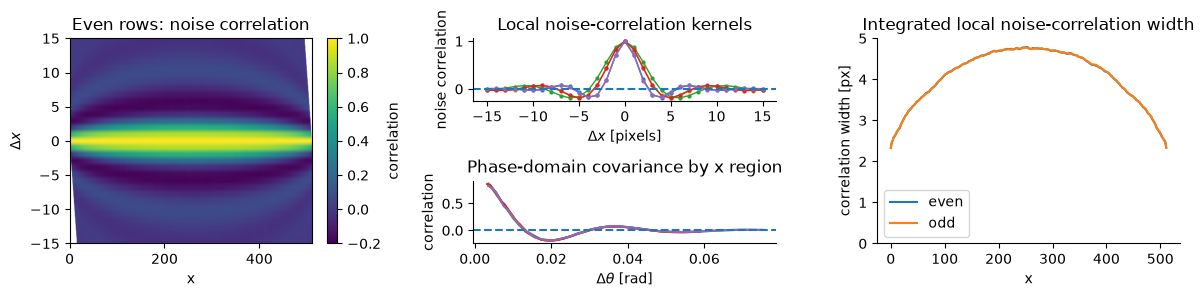

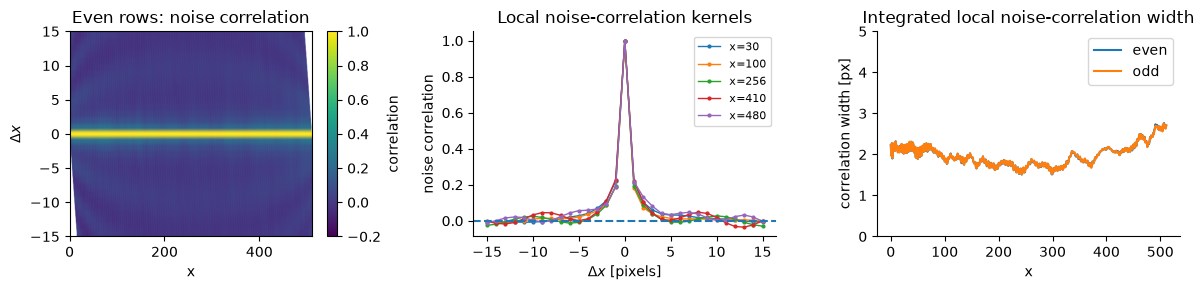

In [8]:
plot_resonant_diagnostics(
    **results_m845,
    with_collapse=True,
    save_path=session_path_m845 / "figures" / "resonant_diagnostics_m845.png",
)
plot_resonant_diagnostics(
    **results_m493,
    with_collapse=False,
    save_path=session_path_m493 / "figures" / "resonant_diagnostics_m493.png",
)

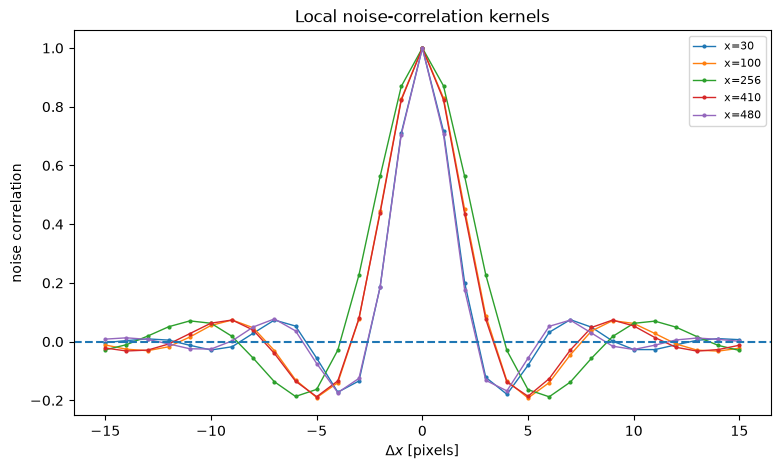

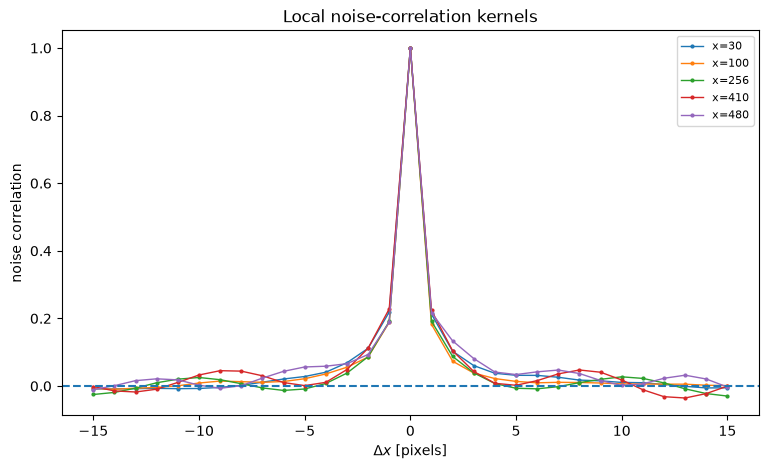

In [9]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plots import (
    plot_local_corr_profiles,
)

plot_local_corr_profiles(results_m845["diagnostics"], xs=(30, 100, 256, 410, 480))
plot_local_corr_profiles(results_m493["diagnostics"], xs=(30, 100, 256, 410, 480))

amplitude = 3.7603 px
x0        = 254.48 px
A         = 271.76 px
R²        = 0.99726
baseline  = 0.0000 px
amplitude = 4.8086 px
x0        = 254.22 px
k         = 0.0037 px
R²        = 0.99393
ratio: 0.45143344043310724


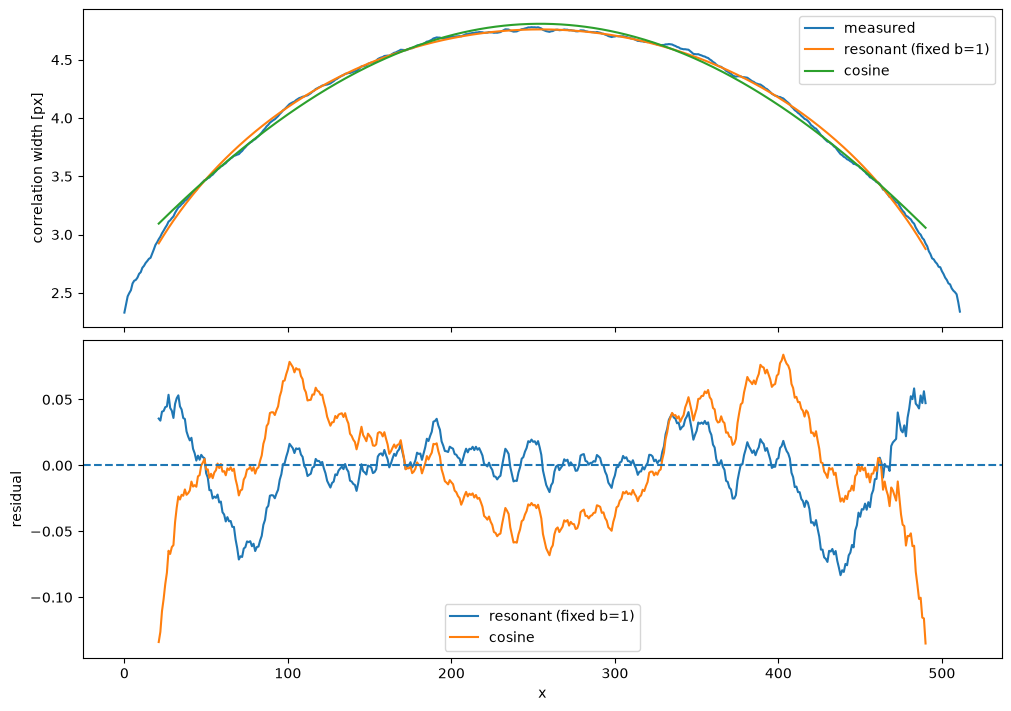

In [10]:
from matplotlib import pyplot as plt
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_velocity_profile import (
    fit_dataset,
    fit_resonant_profile_b1,
    fit_cosine_velocity,
)
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plots_velocity_profile import (
    compare_models,
)

x845, w845, r845, q845 = fit_dataset(results_m845["diagnostics"])

b845 = fit_resonant_profile_b1(x845, w845, edge_margin=20)
amplitude, x0, A = b845["params"]
print(f"amplitude = {amplitude:.4f} px")
print(f"x0        = {x0:.2f} px")
print(f"A         = {A:.2f} px")
print(f"R²        = {b845['r2']:.5f}")

c845 = fit_cosine_velocity(x845, w845, edge_margin=20)
baseline, amplitude, x0, k = c845["params"]

print(f"baseline  = {baseline:.4f} px")
print(f"amplitude = {amplitude:.4f} px")
print(f"x0        = {x0:.2f} px")
print(f"k         = {k:.4f} px")
print(f"R²        = {c845['r2']:.5f}")

print("ratio:", b845["rss"] / c845["rss"])

compare_models(
    x845,
    w845,
    b845,
    c845,
    first_label="resonant (fixed b=1)",
    second_label="cosine",
)
plt.savefig(fig_path / "comparison_resonant_cosine_m845.png")

In [11]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_framewise import (
    bidi_shift_timeseries,
)
from matplotlib import pyplot as plt

bidi_shift, bidi_quality = bidi_shift_timeseries(img_short)

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(bidi_shift)
ax.axhline(0, ls="--")

ax.set_xlabel("frame")
ax.set_ylabel("odd/even x displacement [px]")
ax.set_title("Time-resolved bidirectional phase offset")

plt.show()

NameError: name 'img_short' is not defined

In [12]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_framewise import (
    bidi_shift_x_time,
)

x, bidi_xt, q_xt = bidi_shift_x_time(img_short)

plt.figure(figsize=(11, 6))

plt.imshow(
    bidi_xt,
    aspect="auto",
    origin="lower",
    extent=[x[0], x[-1], 0, img_short.shape[0]],
)

plt.colorbar(label="odd/even displacement [px]")

plt.xlabel("x")
plt.ylabel("frame")
plt.title("Time-dependent bidirectional displacement")

plt.show()

NameError: name 'img_short' is not defined

In [ ]:
fig_path = root_dir.parent / "figures" / "resonancescanningfixes"

session_path = Path(
    # "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
    "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]

suffix = "845"

In [ ]:
session_path = Path(
    # "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
    "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]
img = tiff.imread(file_path).astype(np.float32)
img_short_845 = img[:1000, ...]

session_path = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
    # "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]
img = tiff.imread(file_path).astype(np.float32)
img_short_493 = img[:1000, ...]

# Evaluating bidirectional shifts

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_framewise import (
    bidi_shift_y_time,
)

# y, bidi_yt, quality_yt, margin_yt = (
#     bidi_shift_y_time(
#         img_short,
#         pairs_per_block=8,
#         step_pairs=4,
#         max_shift=5,
#         x_margin=32,
#         smooth_x=1.0,
#     )
# )

y, bidi_yt, quality_yt, margin_yt = bidi_shift_y_time(
    img_short,
    pairs_per_block=32,  # ~64 rows
    step_pairs=8,  # overlapping blocks
    max_shift=5,
    x_margin=32,
    smooth_x=1.0,
)

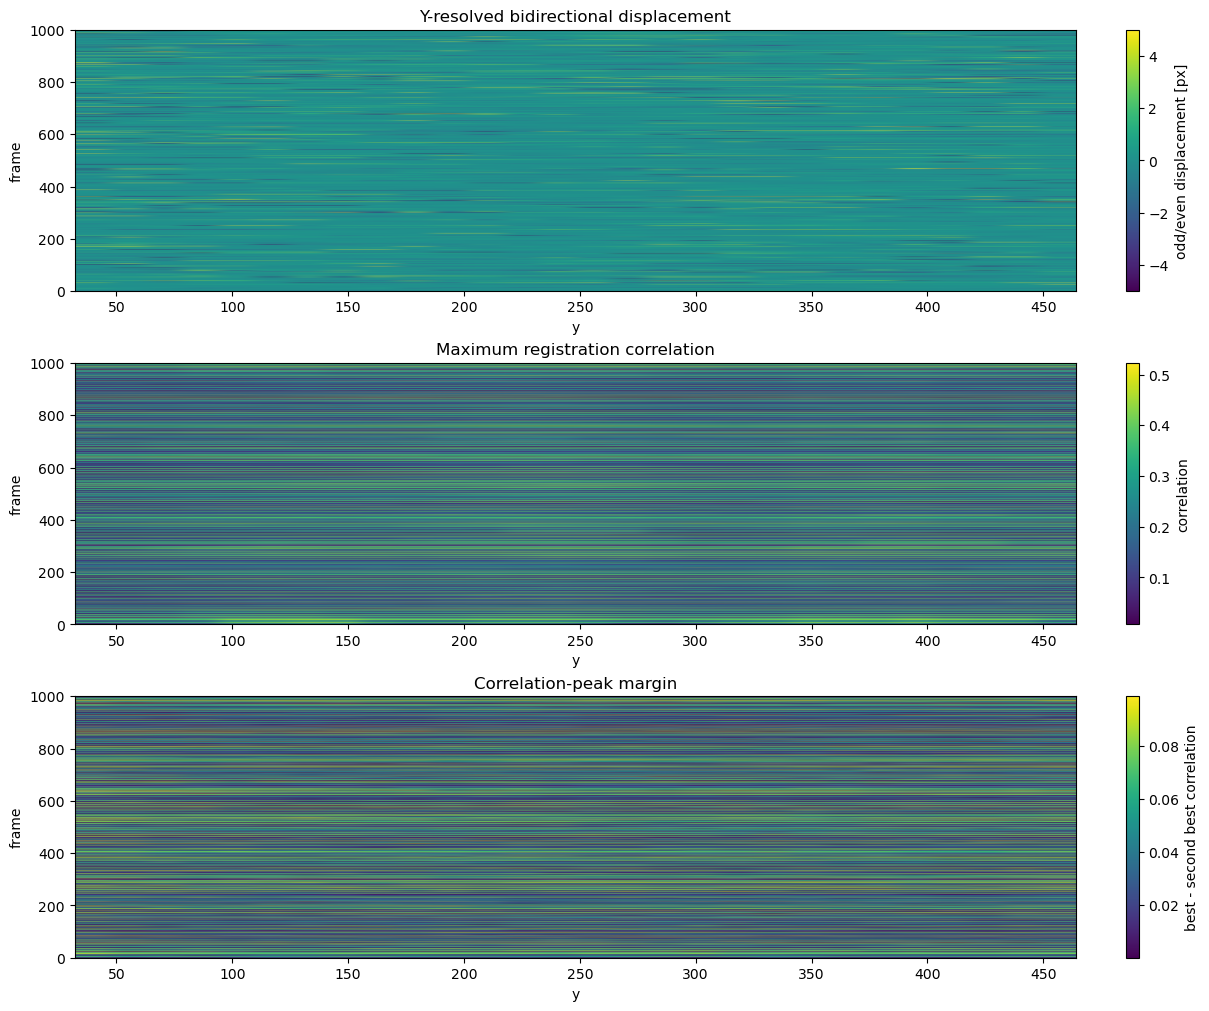

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plots import (
    plot_bidi_y_time,
)

plot_bidi_y_time(
    y,
    bidi_yt,
    quality_yt,
    margin_yt,
)

plt.savefig(fig_path / f"bidi_y_time_m{suffix}.png")

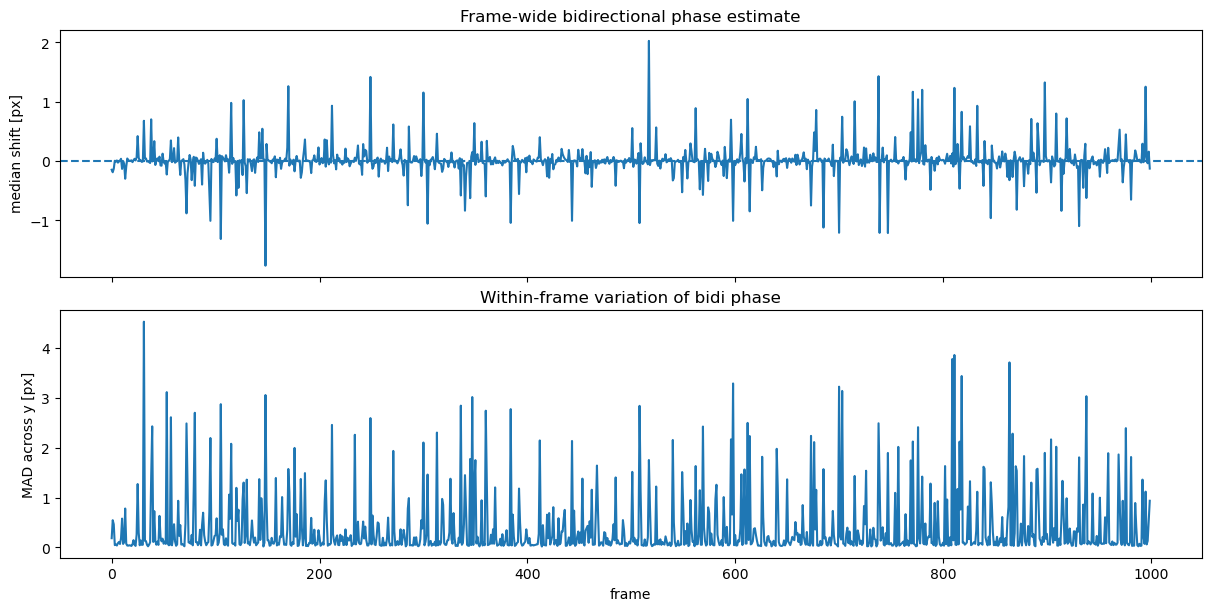

In [ ]:
import numpy as np

median_shift = np.nanmedian(bidi_yt, axis=1)

spread_shift = 1.4826 * np.nanmedian(np.abs(bidi_yt - median_shift[:, None]), axis=1)

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)

ax[0].plot(median_shift)
ax[0].axhline(0, ls="--")
ax[0].set_ylabel("median shift [px]")
ax[0].set_title("Frame-wide bidirectional phase estimate")

ax[1].plot(spread_shift)
ax[1].set_ylabel("MAD across y [px]")
ax[1].set_xlabel("frame")
ax[1].set_title("Within-frame variation of bidi phase")

# plt.show()

plt.savefig(fig_path / f"bidi_y_time_stats_m{suffix}.png")

In [ ]:
median_shift = np.nanmedian(bidi_yt, axis=1)

mad_shift = 1.4826 * np.nanmedian(np.abs(bidi_yt - median_shift[:, None]), axis=1)

median_quality = np.nanmedian(quality_yt, axis=1)

median_margin = np.nanmedian(margin_yt, axis=1)

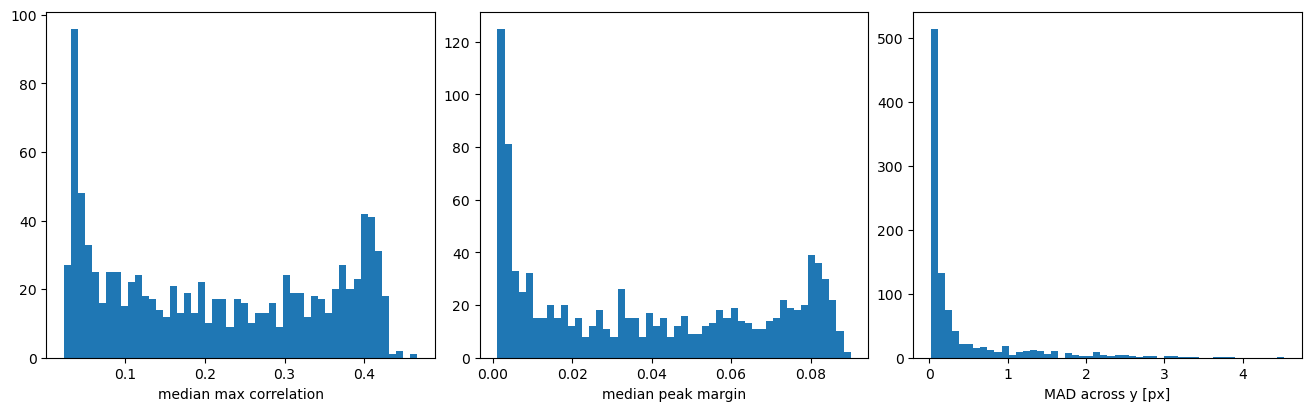

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)

ax[0].hist(median_quality[np.isfinite(median_quality)], bins=50)
ax[0].set_xlabel("median max correlation")

ax[1].hist(median_margin[np.isfinite(median_margin)], bins=50)
ax[1].set_xlabel("median peak margin")

ax[2].hist(mad_shift[np.isfinite(mad_shift)], bins=50)
ax[2].set_xlabel("MAD across y [px]")

plt.savefig(fig_path / f"bidi_y_time_hist_m{suffix}.png")

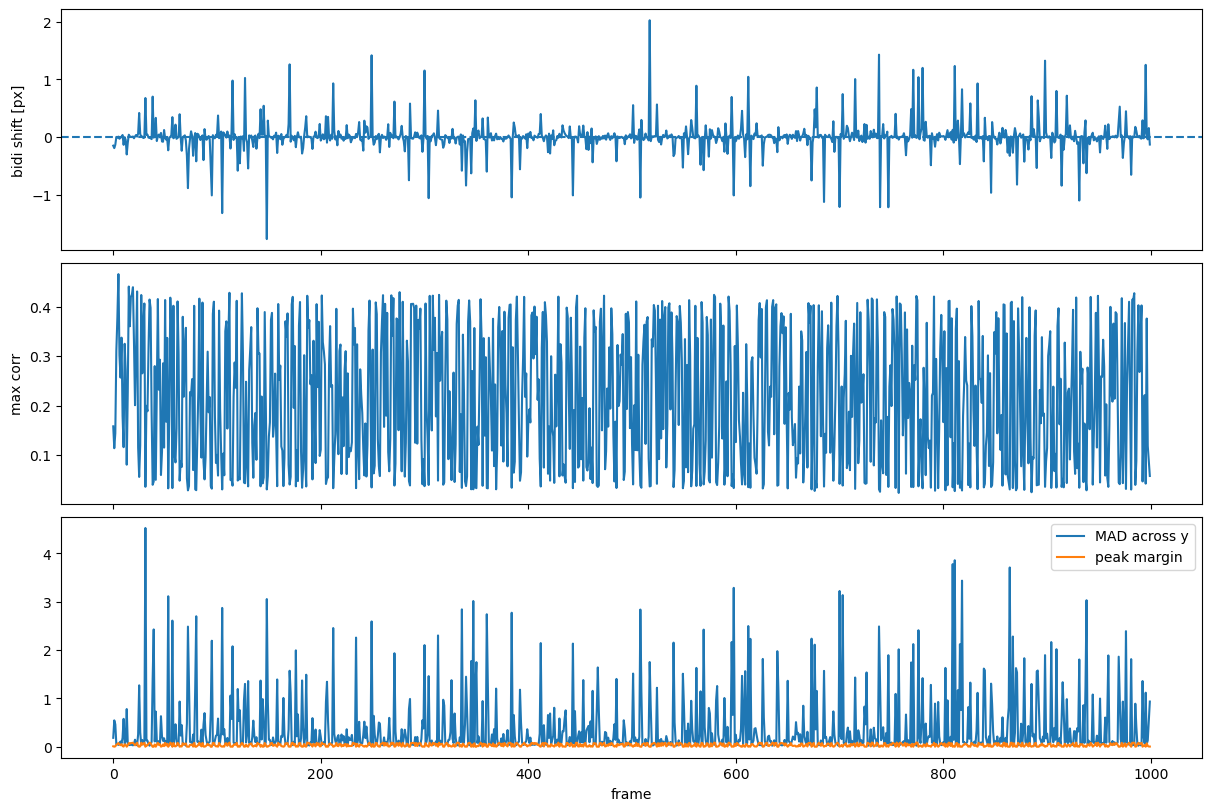

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)

ax[0].plot(median_shift)
ax[0].axhline(0, ls="--")
ax[0].set_ylabel("bidi shift [px]")

ax[1].plot(median_quality)
ax[1].set_ylabel("max corr")

ax[2].plot(mad_shift, label="MAD across y")
ax[2].plot(median_margin, label="peak margin")
ax[2].legend()
ax[2].set_xlabel("frame")

plt.savefig(fig_path / f"bidi_y_time_overview_m{suffix}.png")

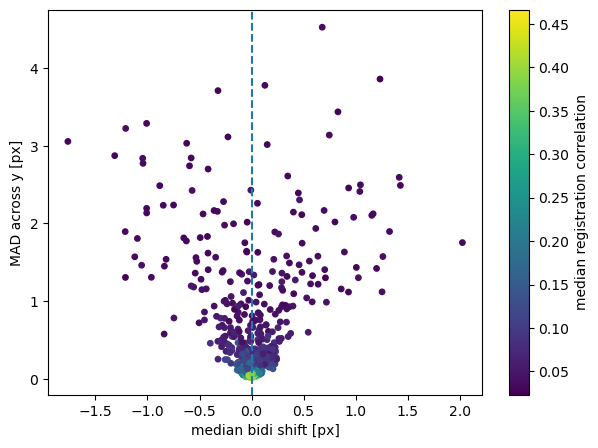

In [141]:
plt.figure(figsize=(7, 5))

sc = plt.scatter(
    median_shift,
    mad_shift,
    c=median_quality,
    s=15,
)

plt.axvline(0, ls="--")

plt.xlabel("median bidi shift [px]")
plt.ylabel("MAD across y [px]")
plt.colorbar(sc, label="median registration correlation")

# plt.show()
plt.savefig(fig_path / f"bidi_y_time_scatter_m{suffix}.png")

even frames: 0.2122882372295228 0.1358899014327373
odd frames: 0.2118704996640701 0.13713771649176534


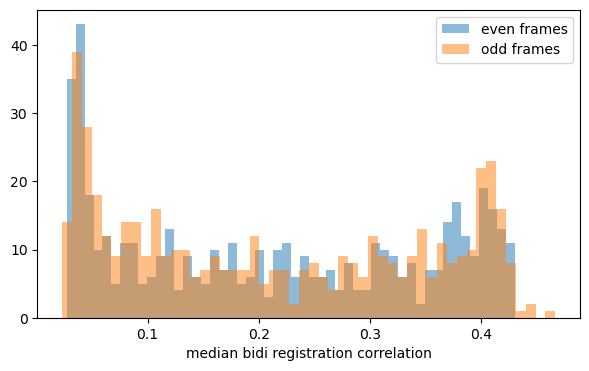

In [149]:
q = median_quality

print(
    "even frames:",
    np.nanmean(q[0::2]),
    np.nanstd(q[0::2]),
)

print(
    "odd frames:",
    np.nanmean(q[1::2]),
    np.nanstd(q[1::2]),
)

plt.figure(figsize=(7, 4))

plt.hist(
    q[0::2],
    bins=50,
    alpha=0.5,
    label="even frames",
)

plt.hist(
    q[1::2],
    bins=50,
    alpha=0.5,
    label="odd frames",
)

plt.xlabel("median bidi registration correlation")
plt.legend()
# plt.show()
plt.savefig(fig_path / f"bidi_y_time_quality_hist_m{suffix}.png")

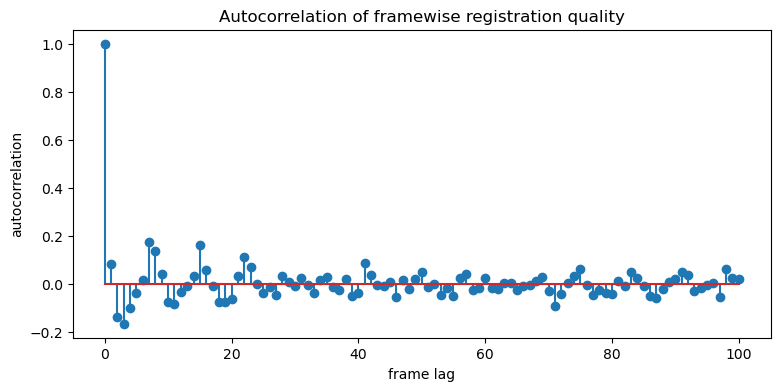

In [ ]:
def autocorrelation(x, max_lag=100):
    x = np.asarray(x, dtype=float)

    valid = np.isfinite(x)
    x = x.copy()

    # simple interpolation over occasional NaNs
    idx = np.arange(len(x))
    x[~valid] = np.interp(
        idx[~valid],
        idx[valid],
        x[valid],
    )

    x -= x.mean()

    ac = np.correlate(x, x, mode="full")[len(x) - 1 :]

    ac /= ac[0]

    return ac[: max_lag + 1]


ac = autocorrelation(median_quality, max_lag=100)

plt.figure(figsize=(9, 4))
plt.stem(np.arange(len(ac)), ac)

plt.xlabel("frame lag")
plt.ylabel("autocorrelation")
plt.title("Autocorrelation of framewise registration quality")
# plt.show()
plt.savefig(fig_path / f"autocorrelation_m{suffix}.png")

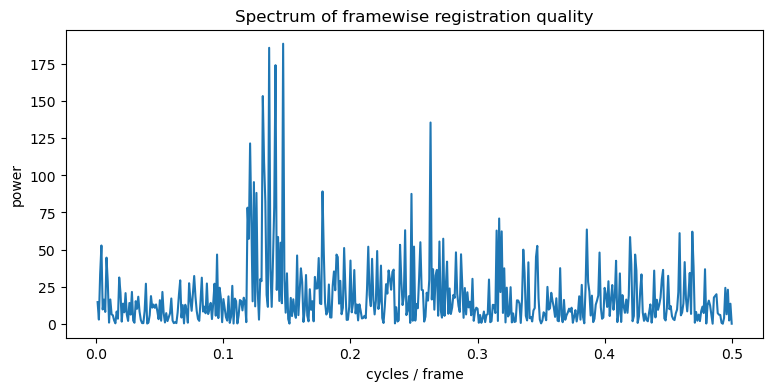

In [ ]:
q0 = median_quality.copy()

valid = np.isfinite(q0)

q0[~valid] = np.interp(
    np.flatnonzero(~valid),
    np.flatnonzero(valid),
    q0[valid],
)

q0 -= q0.mean()

power = np.abs(np.fft.rfft(q0)) ** 2

freq = np.fft.rfftfreq(len(q0), d=1)

plt.figure(figsize=(9, 4))

plt.plot(freq[1:], power[1:])

plt.xlabel("cycles / frame")
plt.ylabel("power")
plt.title("Spectrum of framewise registration quality")
# plt.show()
plt.savefig(fig_path / f"spectrum_m{suffix}.png")

In [148]:
median_quality

array([0.15803709, 0.1137128 , 0.143999  , 0.31152147, 0.37856678,
       0.46635112, 0.30205898, 0.25678331, 0.3377044 , 0.17894612,
       0.11581269, 0.32525425, 0.2706444 , 0.08036203, 0.22650844,
       0.44121552, 0.36072504, 0.42012253, 0.42506334, 0.43984692,
       0.32762344, 0.20080811, 0.30924802, 0.43127912, 0.11531599,
       0.05554466, 0.12001443, 0.42405487, 0.26536571, 0.3638258 ,
       0.4068868 , 0.0355102 , 0.19954894, 0.18864127, 0.31530516,
       0.41487397, 0.39810163, 0.18472021, 0.03967003, 0.04617306,
       0.2800199 , 0.0496768 , 0.23218731, 0.4158552 , 0.23216514,
       0.29302496, 0.05940668, 0.10686335, 0.28564567, 0.11494244,
       0.41392002, 0.16744078, 0.33717835, 0.0324467 , 0.17826297,
       0.41865056, 0.35453899, 0.03291317, 0.40226216, 0.10195224,
       0.0849507 , 0.15352233, 0.41105396, 0.30441278, 0.04790577,
       0.08772779, 0.07569884, 0.37997485, 0.21812047, 0.31353365,
       0.35765561, 0.05266646, 0.02835586, 0.03706455, 0.22729

# Checking 8-frame periodicity

In [ ]:
frame_mean = np.nanmean(img_short, axis=(1, 2))
frame_std = np.nanstd(img_short, axis=(1, 2))

# A robust high-frequency / contrast measure
gx = np.diff(img_short, axis=2)
gy = np.diff(img_short, axis=1)

grad_energy_x = np.nanmean(gx**2, axis=(1, 2))
grad_energy_y = np.nanmean(gy**2, axis=(1, 2))

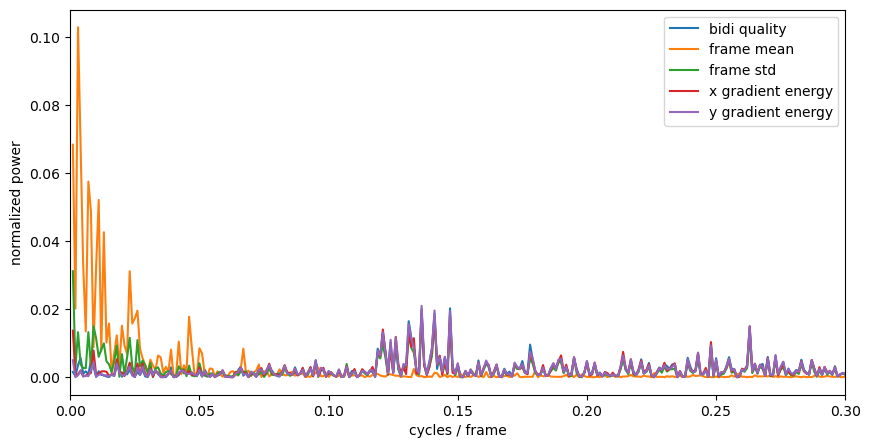

In [ ]:
def normalized_power_spectrum(x):
    x = np.asarray(x, dtype=float)

    good = np.isfinite(x)
    ii = np.arange(len(x))
    x[~good] = np.interp(ii[~good], ii[good], x[good])

    x -= x.mean()

    power = np.abs(np.fft.rfft(x)) ** 2
    power /= power.sum()

    freq = np.fft.rfftfreq(len(x))

    return freq, power


signals = {
    "bidi quality": median_quality,
    "frame mean": frame_mean,
    "frame std": frame_std,
    "x gradient energy": grad_energy_x,
    "y gradient energy": grad_energy_y,
}

plt.figure(figsize=(10, 5))

for name, sig in signals.items():
    f, p = normalized_power_spectrum(sig)
    plt.plot(f[1:], p[1:], label=name)

plt.xlim(0, 0.3)
plt.xlabel("cycles / frame")
plt.ylabel("normalized power")
plt.legend()
# plt.show()
plt.savefig(fig_path / f"normalized_power_spectrum_m{suffix}.png")

In [161]:
results_845 = diagnose_resonant_scan(img_short_845)
results_493 = diagnose_resonant_scan(img_short_493)

# Velocity profile

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_velocity_profile import (
    fit_resonant_profile,
)

width_even = results_845["metric_even"]["corr_area"]
width_odd = results_845["metric_odd"]["corr_area"]

width = 0.5 * (width_even + width_odd)

x = np.arange(len(width))

fit = fit_resonant_profile(
    x,
    width,
    edge_margin=20,
)

In [163]:
print(f"{width_even=}, {width_odd=}")

width_even=array([2.44913851, 2.45455794, 2.47552812, 2.5186642 , 2.52813274,
       2.64312617, 2.63487062, 2.63930654, 2.63478159, 2.68985605,
       2.67165087, 2.7637712 , 2.74195319, 2.767056  , 2.76753946,
       2.81151652, 2.79665205, 2.85557564, 2.86993862, 2.92140817,
       2.91480212, 2.98499072, 2.98320369, 3.02385723, 3.0327554 ,
       3.08889453, 3.09420477, 3.11802732, 3.095282  , 3.15313066,
       3.15283731, 3.1955669 , 3.21238229, 3.25815619, 3.23897355,
       3.26116464, 3.24480162, 3.26520904, 3.25568763, 3.32041172,
       3.3567297 , 3.38870581, 3.36673637, 3.40158952, 3.39672465,
       3.41574096, 3.39909406, 3.46217822, 3.47042881, 3.48876396,
       3.46923447, 3.49617326, 3.48272107, 3.50349179, 3.49591781,
       3.5482526 , 3.55597435, 3.59566804, 3.5912658 , 3.61489787,
       3.59700491, 3.61178174, 3.60451468, 3.65284911, 3.6518165 ,
       3.68157908, 3.66821034, 3.69611455, 3.67725733, 3.69292685,
       3.6774308 , 3.7186631 , 3.73269827, 3.766587

In [164]:
baseline, amplitude, x0, A = fit["params"]

print(f"baseline  = {baseline:.4f} px")
print(f"amplitude = {amplitude:.4f} px")
print(f"x0        = {x0:.2f} px")
print(f"A         = {A:.2f} px")
print(f"R²        = {fit['r2']:.5f}")

baseline  = 0.0000 px
amplitude = 4.7727 px
x0        = 253.93 px
A         = 297.80 px
R²        = 0.99769


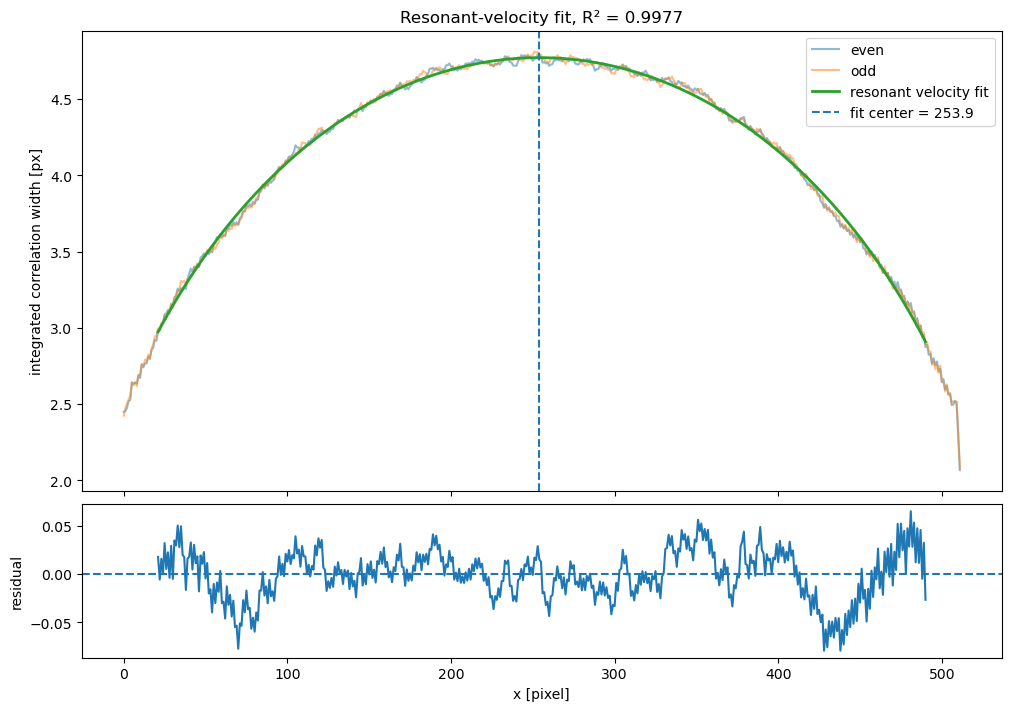

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plots_velocity_profile import (
    plot_resonant_fit,
)

plot_resonant_fit(
    x,
    width_even,
    width_odd,
    fit,
)

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_velocity_profile import (
    fit_resonant_profile,
    fit_quadratic_profile,
)

rss_resonant = np.sum(fit["residuals"] ** 2)
quad = fit_quadratic_profile(
    x,
    width,
    edge_margin=20,
)

print("resonant RSS:", rss_resonant)

print("quadratic RSS:", quad["rss"])

print("ratio:", quad["rss"] / rss_resonant)

resonant RSS: 0.303138755616075
quadratic RSS: 0.5816507776178129
ratio: 1.9187608540376577


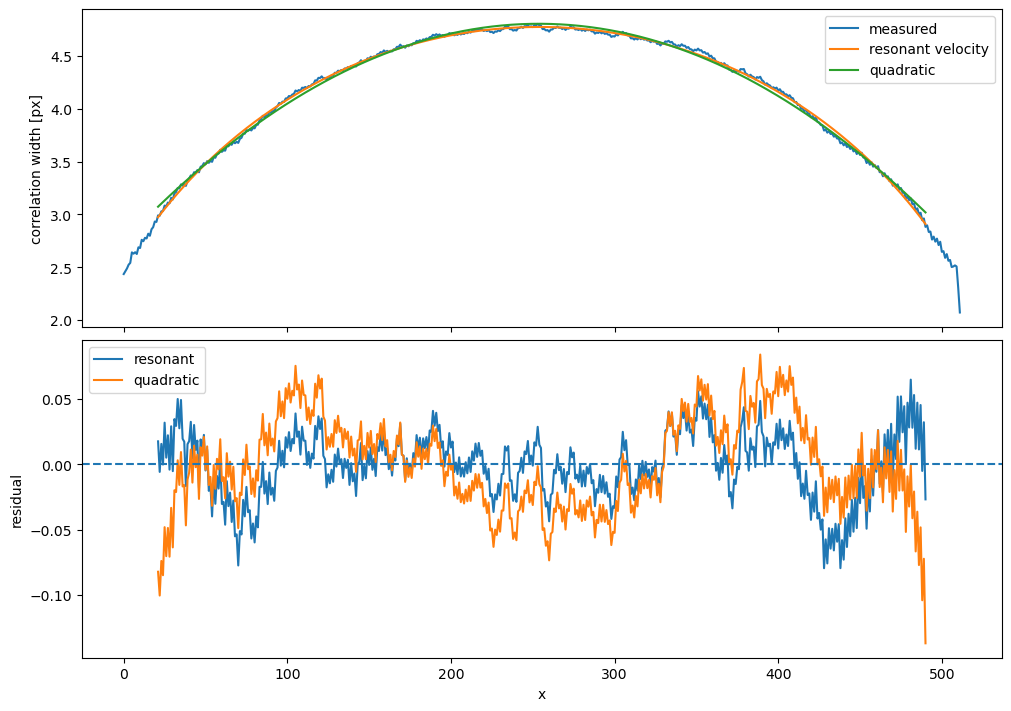

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plots_velocity_profile import (
    compare_models,
)

compare_models(
    x,
    width,
    fit,
    quad,
)

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_velocity_profile import (
    fit_dataset,
)

x845, w845, r845, q845 = fit_dataset(results_845)

x493, w493, r493, q493 = fit_dataset(results_493)

baseline  = 0.0000 px
amplitude = 4.7727 px
x0        = 253.93 px
A         = 297.80 px
R²        = 0.99769
ratio: 1.9187608540376577
baseline  = 1.9492 px
amplitude = 0.0000 px
x0        = 287.09 px
A         = 1343.54 px
R²        = -0.01863
ratio: 1.000000000367365


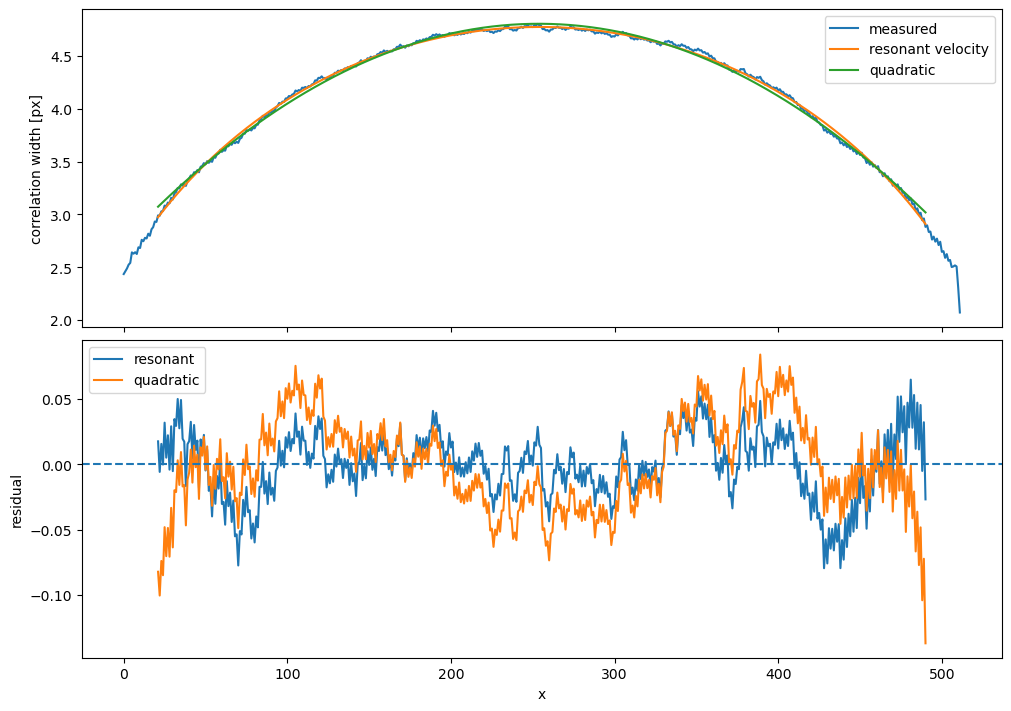

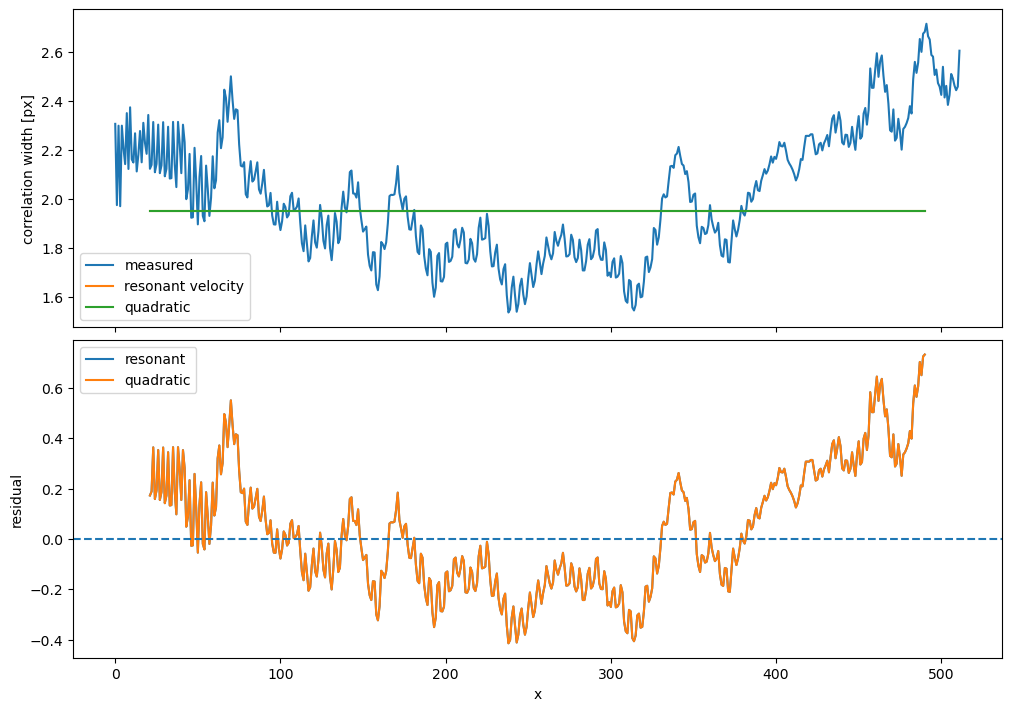

In [ ]:
compare_models(
    x845,
    w845,
    r845,
    q845,
)
baseline, amplitude, x0, A = r845["params"]
print(f"baseline  = {baseline:.4f} px")
print(f"amplitude = {amplitude:.4f} px")
print(f"x0        = {x0:.2f} px")
print(f"A         = {A:.2f} px")
print(f"R²        = {r845['r2']:.5f}")
plt.savefig(fig_path / "r845_comparison.png")

rss_resonant = np.sum(r845["residuals"] ** 2)
print("ratio:", q845["rss"] / rss_resonant)

compare_models(
    x493,
    w493,
    r493,
    q493,
)
baseline, amplitude, x0, A = r493["params"]
print(f"baseline  = {baseline:.4f} px")
print(f"amplitude = {amplitude:.4f} px")
print(f"x0        = {x0:.2f} px")
print(f"A         = {A:.2f} px")
print(f"R²        = {r493['r2']:.5f}")
plt.savefig(fig_path / "r493_comparison.png")
rss_resonant = np.sum(r493["residuals"] ** 2)
print("ratio:", q493["rss"] / rss_resonant)

In the resonant model, fixing the baseline at b=1 (should be lowest value) gives 3 parameter-model for measurements linearly spaaced in physical space, but with heterogeneous correlation length

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_velocity_profile import (
    fit_resonant_profile_b1,
)

b845 = fit_resonant_profile_b1(x845, w845, edge_margin=20)
amplitude, x0, A = b845["params"]
print(f"amplitude = {amplitude:.4f} px")
print(f"x0        = {x0:.2f} px")
print(f"A         = {A:.2f} px")
print(f"R²        = {b845['r2']:.5f}")

amplitude = 3.7621 px
x0        = 254.00 px
A         = 271.67 px
R²        = 0.99658


Cosine model would describe the case of measurement points linearly spaced in time

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_velocity_profile import (
    fit_cosine_velocity,
)

c845 = fit_cosine_velocity(x845, w845, edge_margin=20)
baseline, amplitude, x0, k = c845["params"]

print(f"baseline  = {baseline:.4f} px")
print(f"amplitude = {amplitude:.4f} px")
print(f"x0        = {x0:.2f} px")
print(f"k         = {k:.4f} px")
print(f"R²        = {c845['r2']:.5f}")

print("ratio:", b845["rss"] / c845["rss"])

baseline  = 0.0000 px
amplitude = 4.8106 px
x0        = 253.63 px
k         = 0.0037 px
R²        = 0.99360
ratio: 0.5337254313221634


Baseline-fixed, resonant model is clearly favored, pointing towards an actually performed linearization, which however left a position-dependent correlation structure (other than in newer data)

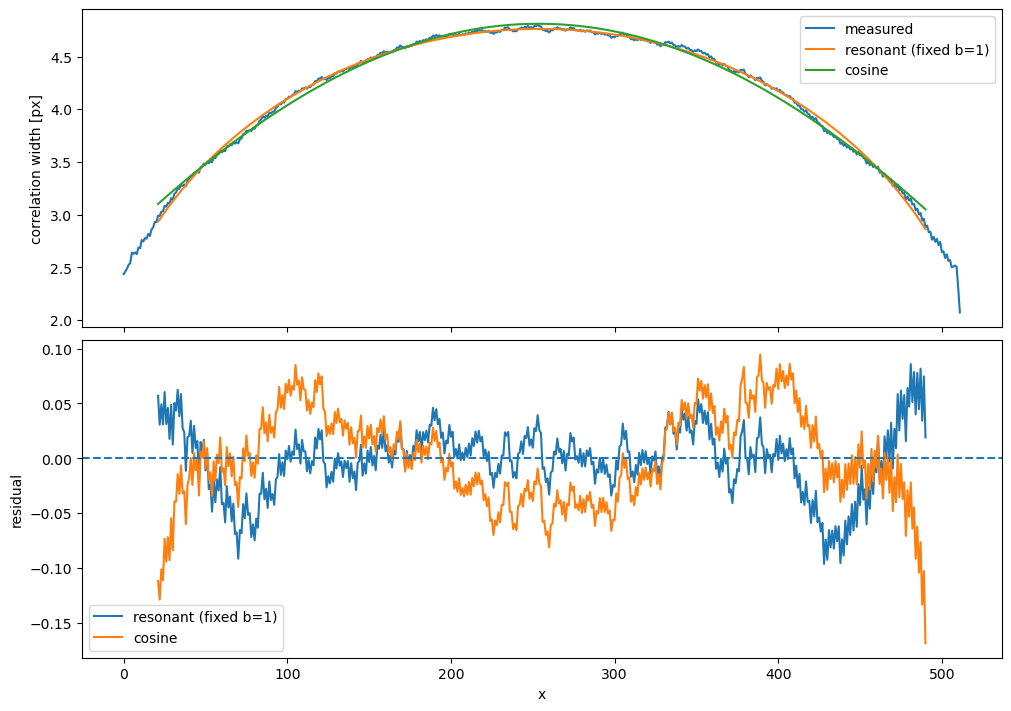

In [196]:
compare_models(
    x845,
    w845,
    b845,
    c845,
    first_label="resonant (fixed b=1)",
    second_label="cosine",
)
plt.savefig(fig_path / "comparison_resonant_cosine_m845.png")

current hypothesis:

```The m845 data show an exceptionally strong spatial-correlation footprint produced by resonant-scan reconstruction. The dependence on reconstructed x is highly consistent with the scanner velocity expressed in already-linearized spatial coordinates.```

# Forward model:
## resonant sampling + reconstruction → predicted C(x,Δx)

In [210]:
session_path = Path(
    # "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
    "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]
img = tiff.imread(file_path).astype(np.float32)

In [211]:
max_lag = 15
z = frame_difference_noise(img, False)
corr_even = spatial_noise_correlation(z, parity=0, max_lag=max_lag)
corr_odd = spatial_noise_correlation(z, parity=1, max_lag=max_lag)

In [216]:
suffix = "845"

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.forward_model import (
    fit_phase_sinc_fixed_geometry,
)

kernel_fit = fit_phase_sinc_fixed_geometry(
    corr_even,
    corr_odd,
    x0=254.00,  # values from previous fit
    A=271.67,  # values from previous fit
    max_fit_lag=15,
)

print("tau_theta:", kernel_fit["tau_theta"])

print("alpha:", kernel_fit["alpha"])

print("R²:", kernel_fit["r2"])

tau_theta: 0.015890608670754668
alpha: 0.8373800796108729
R²: 0.9622082846272096


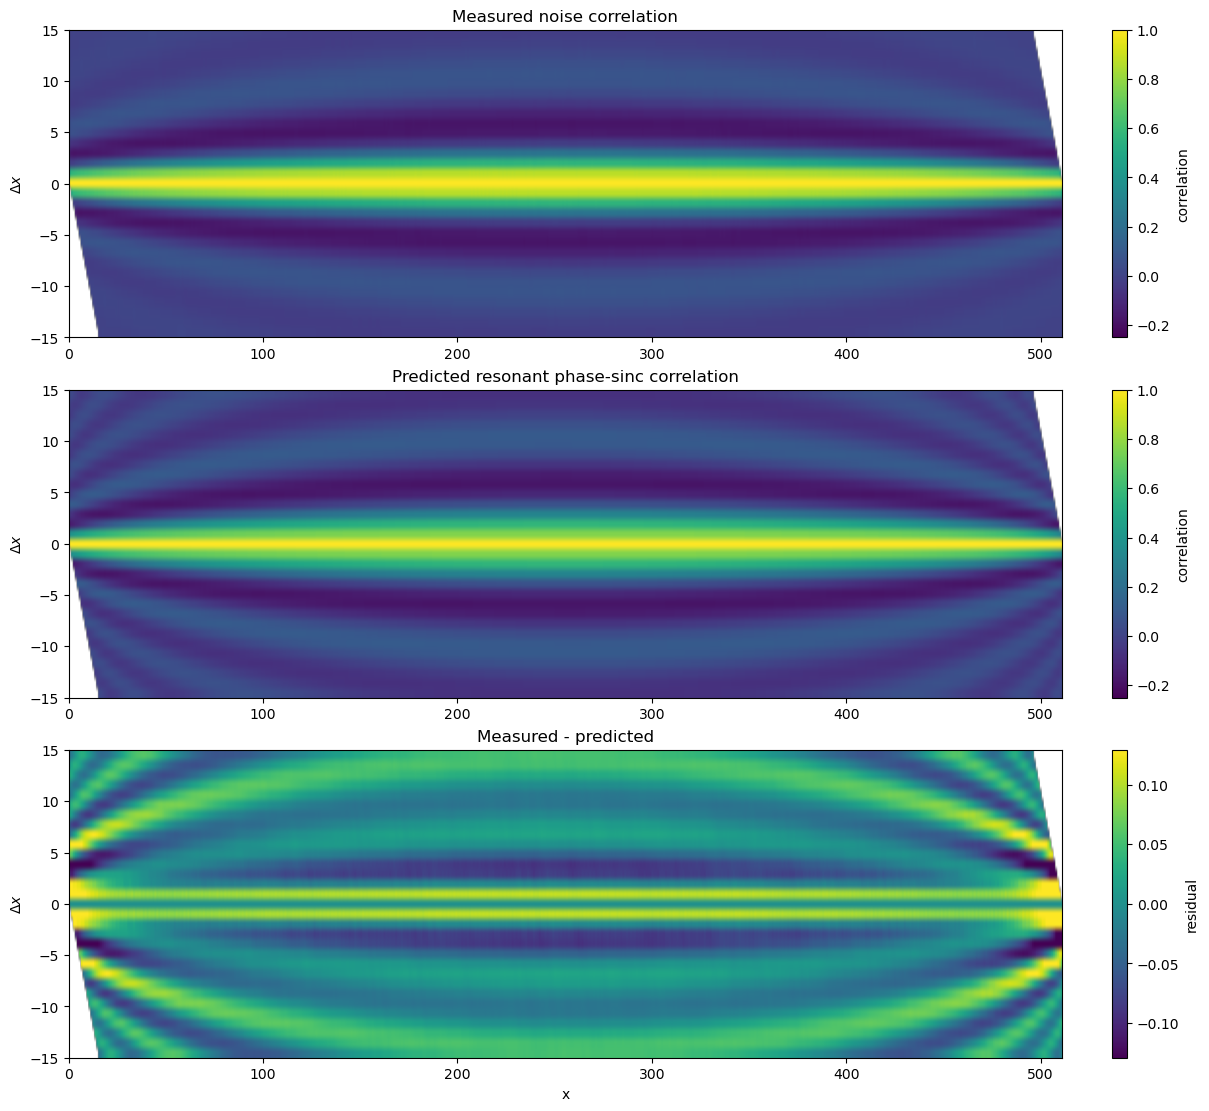

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plot_forward_model import (
    plot_covariance_forward_model,
)

predicted, residual = plot_covariance_forward_model(
    corr_even,
    corr_odd,
    kernel_fit,
)
plt.savefig(fig_path / f"covariance_forward_model_m{suffix}.png")

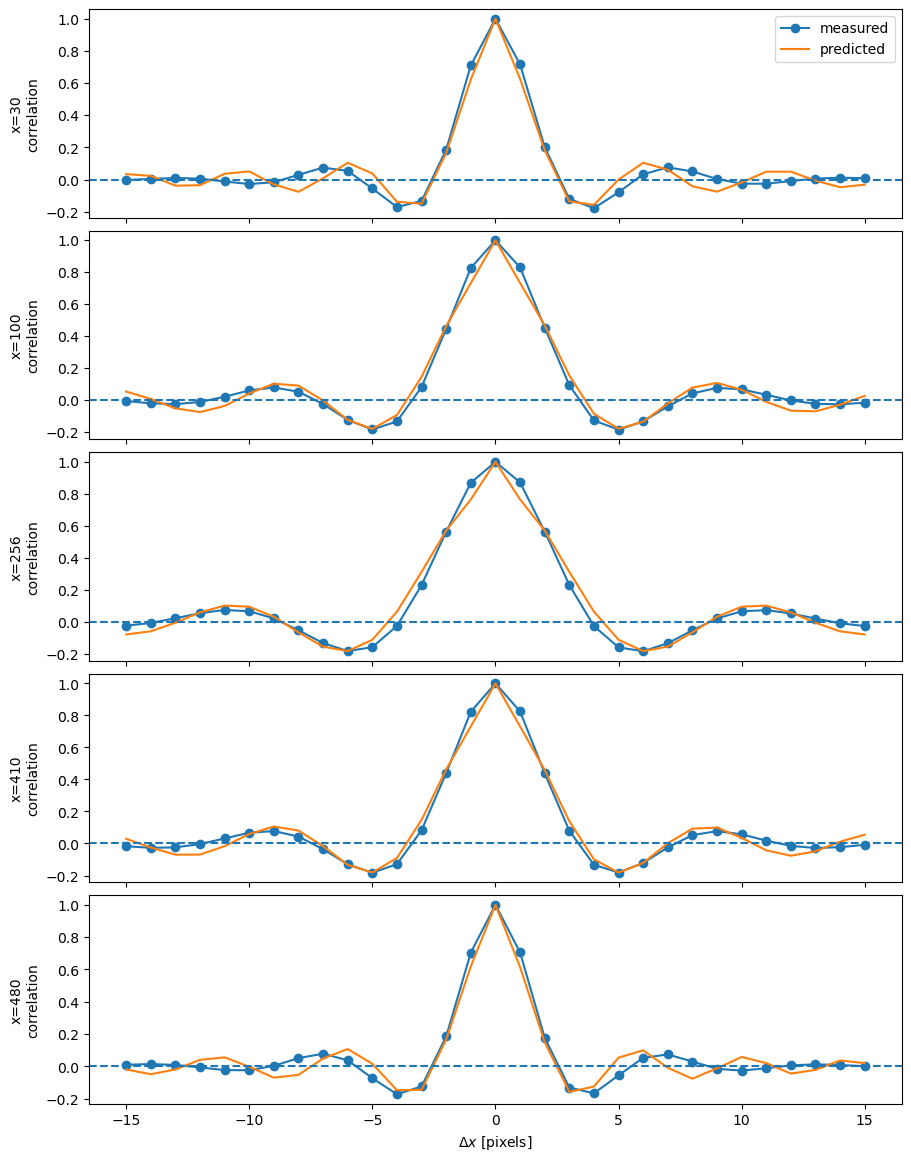

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plot_forward_model import (
    plot_measured_vs_predicted_kernels,
)

plot_measured_vs_predicted_kernels(
    corr_even,
    corr_odd,
    predicted,
)
plt.savefig(fig_path / f"measured_vs_predicted_kernels_m{suffix}.png")

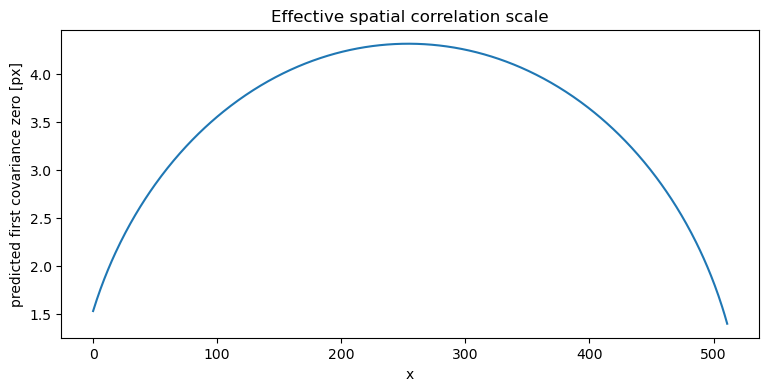

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.forward_model import (
    first_zero_profile,
)

zero_profile = first_zero_profile(
    512,
    kernel_fit["x0"],
    kernel_fit["A"],
    kernel_fit["tau_theta"],
)

plt.figure(figsize=(9, 4))
plt.plot(zero_profile)

plt.xlabel("x")
plt.ylabel("predicted first covariance zero [px]")
plt.title("Effective spatial correlation scale")
# plt.show()
plt.savefig(fig_path / f"first_zero_profile_m{suffix}.png")

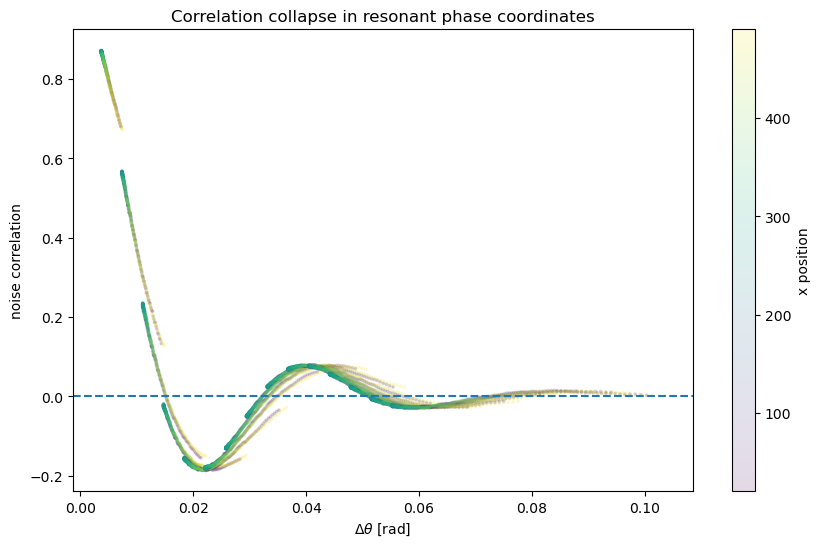

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.forward_model import (
    phase_collapse_data,
)

collapsed = phase_collapse_data(
    corr_even,
    corr_odd,
    x0=254.0,
    A=271.67,
    max_lag=15,
)

plt.figure(figsize=(10, 6))

sc = plt.scatter(
    collapsed["dtheta"],
    collapsed["corr"],
    c=collapsed["x"],
    s=3,
    alpha=0.15,
)

plt.axhline(0, ls="--")

plt.xlabel(r"$\Delta\theta$ [rad]")
plt.ylabel("noise correlation")

plt.colorbar(sc, label="x position")

plt.title("Correlation collapse in resonant phase coordinates")

# plt.show()
plt.savefig(fig_path / f"correlation_collapse_m{suffix}.png")

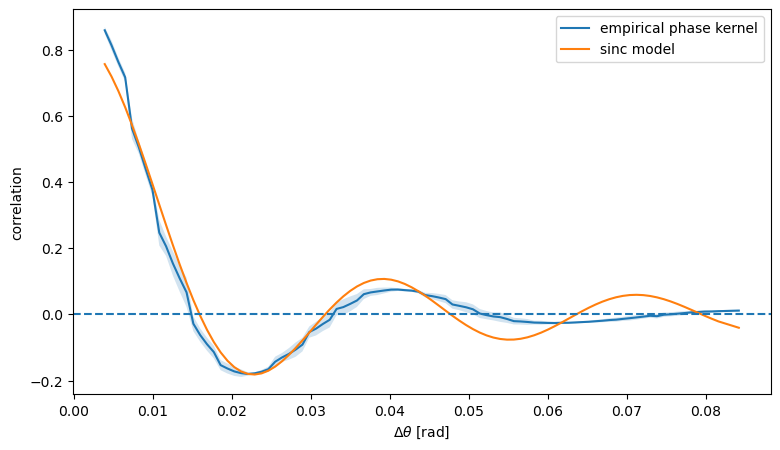

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    estimate_phase_kernel,
)

theta_bin, K, K_std, count = estimate_phase_kernel(
    collapsed,
    n_bins=120,
)

good = np.isfinite(K)

plt.figure(figsize=(9, 5))

plt.plot(
    theta_bin[good],
    K[good],
    label="empirical phase kernel",
)

plt.fill_between(
    theta_bin[good],
    K[good] - K_std[good],
    K[good] + K_std[good],
    alpha=0.2,
)

# Current sinc prediction
tau = kernel_fit["tau_theta"]
alpha = kernel_fit["alpha"]

plt.plot(
    theta_bin[good],
    alpha * np.sinc(theta_bin[good] / tau),
    label="sinc model",
)

plt.axhline(0, ls="--")

plt.xlabel(r"$\Delta\theta$ [rad]")
plt.ylabel("correlation")
plt.legend()

# plt.show()
plt.savefig(fig_path / f"phase_kernel_m{suffix}.png")

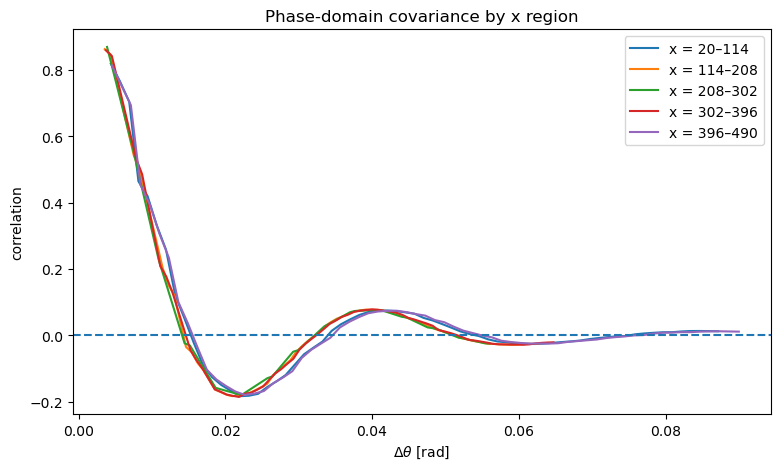

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plot_forward_model import (
    plot_phase_kernel_by_x,
)

plot_phase_kernel_by_x(collapsed)
plt.savefig(fig_path / f"phase_kernel_by_x_m{suffix}.png")

In [ ]:
from diagnostics_forward_model import (
    fit_damped_sinc,
    damped_sinc_kernel,
)

damped_fit = fit_damped_sinc(collapsed)

print(f"alpha = {damped_fit['alpha']:.4f}")
print(f"tau   = {damped_fit['tau']:.5f} rad")
print(f"sigma = {damped_fit['sigma']:.5f} rad")
print(f"R²    = {damped_fit['r2']:.5f}")


plt.figure(figsize=(9, 5))

plt.plot(
    theta_bin[good],
    K[good],
    label="empirical",
    linewidth=2,
)

plt.plot(
    theta_bin[good],
    kernel_fit["alpha"] * np.sinc(theta_bin[good] / kernel_fit["tau_theta"]),
    label="sinc",
)

plt.plot(
    theta_bin[good],
    damped_sinc_kernel(
        theta_bin[good],
        damped_fit["alpha"],
        damped_fit["tau"],
        damped_fit["sigma"],
    ),
    label="damped sinc",
)

plt.axhline(0, ls="--")

plt.xlabel(r"$\Delta\theta$ [rad]")
plt.ylabel("correlation")
plt.legend()

# plt.show()
plt.savefig(fig_path / f"phase_kernel_damped_fit_m{suffix}.png")

alpha = 0.9299
tau   = 0.01425 rad
sigma = 0.03587 rad
R²    = 0.98151


NameError: name 'theta_bin' is not defined

<Figure size 900x500 with 0 Axes>

In [19]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    fit_joint_resonant_covariance,
)

joint_fit = fit_joint_resonant_covariance(
    results_845ad["corr_even"],
    results_845ad["corr_odd"],
)

for key in [
    "x0",
    "A",
    "left_turn",
    "right_turn",
    "alpha",
    "tau",
    "sigma",
    "r2",
]:
    print(f"{key:>12s} = " f"{joint_fit[key]:.6f}")

          x0 = 254.331857
           A = 293.631521
   left_turn = -39.299664
  right_turn = 547.963378
       alpha = 0.929869
         tau = 0.014247
       sigma = 0.035861
          r2 = 0.981506


In [21]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    geometry_profile_grid,
)

profile = geometry_profile_grid(
    results_845ad["corr_even"],
    results_845ad["corr_odd"],
)

In [ ]:
suffix = "845"

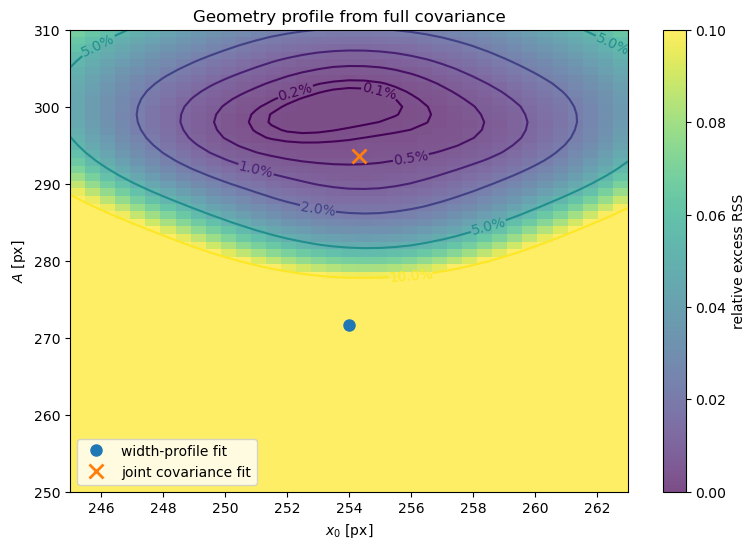

In [24]:
rss = profile["rss"]

rss_min = np.nanmin(rss)

relative = rss / rss_min - 1

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(
    relative,
    origin="lower",
    aspect="auto",
    extent=[
        profile["x0"][0],
        profile["x0"][-1],
        profile["A"][0],
        profile["A"][-1],
    ],
    vmin=0,
    vmax=0.10,
    alpha=0.7,
)

levels = [
    0.001,
    0.002,
    0.005,
    0.01,
    0.02,
    0.05,
    0.10,
]
X0, AA = np.meshgrid(
    profile["x0"],
    profile["A"],
)
cs = plt.contour(
    X0,
    AA,
    relative,
    levels=levels,
)

plt.clabel(
    cs,
    inline=True,
    fmt=lambda v: f"{100*v:.1f}%",
)

fig.colorbar(
    im,
    ax=ax,
    label="relative excess RSS",
)

# Width-profile estimate
ax.plot(
    254.00,
    271.67,
    "o",
    markersize=8,
    label="width-profile fit",
)

# Full covariance estimate
ax.plot(
    joint_fit["x0"],
    joint_fit["A"],
    "x",
    markersize=10,
    mew=2,
    label="joint covariance fit",
)

ax.set_xlabel(r"$x_0$ [px]")
ax.set_ylabel(r"$A$ [px]")

ax.set_title("Geometry profile from full covariance")

ax.legend()

# plt.show()
plt.savefig(fig_path / f"geometry_profile_relative_excess_rss_m{suffix}.png")

In [25]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    correlation_observations,
    nonparametric_collapse_score,
)

x_obs, lag_obs, c_obs = correlation_observations(
    results_845ad["corr_even"],
    results_845ad["corr_odd"],
    max_fit_lag=15,
    x_margin=20,
)
x0_values = np.linspace(248, 260, 49)

A_values = np.linspace(260, 315, 56)

collapse_score = np.full((len(A_values), len(x0_values)), np.nan)

for ia, A in enumerate(A_values):
    for ix, x0 in enumerate(x0_values):

        collapse_score[ia, ix] = nonparametric_collapse_score(
            x_obs,
            lag_obs,
            c_obs,
            x0=x0,
            A=A,
            n_bins=120,  # seems robust to changes (tested 80-200)
        )

nonparametric x0: 255.0
nonparametric A: 293.0


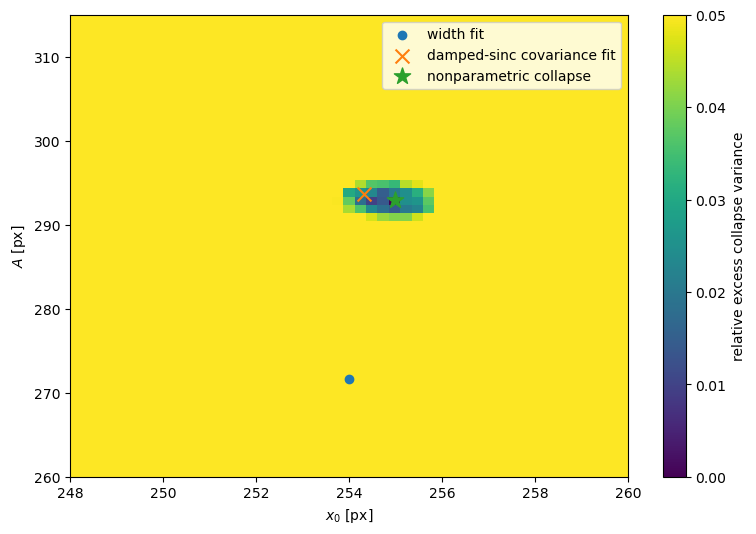

In [26]:
minimum = np.nanmin(collapse_score)

relative = collapse_score / minimum - 1

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(
    relative,
    origin="lower",
    aspect="auto",
    extent=[
        x0_values[0],
        x0_values[-1],
        A_values[0],
        A_values[-1],
    ],
    vmin=0,
    vmax=0.05,
)

fig.colorbar(
    im,
    ax=ax,
    label="relative excess collapse variance",
)

# previous estimates
ax.scatter(
    254.0,
    271.67,
    label="width fit",
)

ax.scatter(
    joint_fit["x0"],
    joint_fit["A"],
    marker="x",
    s=100,
    label="damped-sinc covariance fit",
)

iy, ix = np.unravel_index(np.nanargmin(collapse_score), collapse_score.shape)

x0_nonparam = x0_values[ix]
A_nonparam = A_values[iy]

ax.scatter(
    x0_nonparam,
    A_nonparam,
    marker="*",
    s=150,
    label="nonparametric collapse",
)

ax.set_xlabel(r"$x_0$ [px]")
ax.set_ylabel(r"$A$ [px]")
ax.legend()

# plt.show()
plt.savefig(fig_path / f"collapse_score_plot_m{suffix}.png")

print("nonparametric x0:", x0_nonparam)
print("nonparametric A:", A_nonparam)

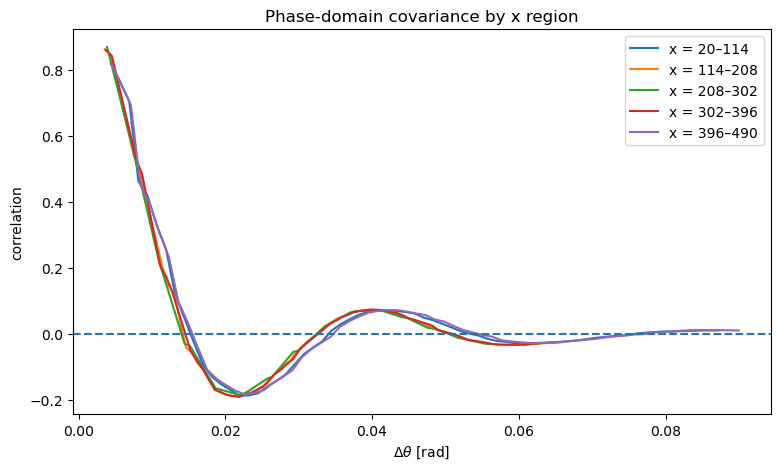

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plot_forward_model import (
    plot_phase_kernel_by_x,
)

collapsed_272 = phase_collapse_data(
    results_845ad["corr_even"],
    results_845ad["corr_odd"],
    x0=254.0,
    A=271.67,
)

plot_phase_kernel_by_x(collapsed_272)
plt.savefig(fig_path / f"collapsed_272_plot_m{suffix}.png")

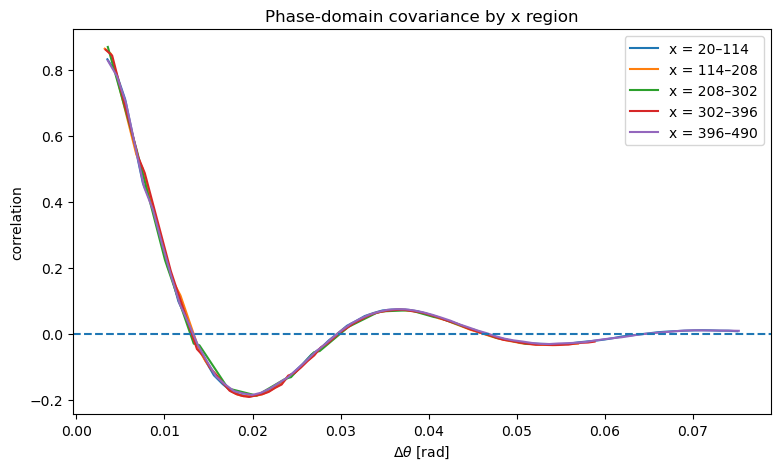

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    phase_collapse_data,
)

collapsed_294 = phase_collapse_data(
    results_845ad["corr_even"],
    results_845ad["corr_odd"],
    x0=joint_fit["x0"],
    A=joint_fit["A"],
)

plot_phase_kernel_by_x(collapsed_294)
plt.savefig(fig_path / f"collapsed_294_plot_m{suffix}.png")

```
The abnormal x-dependent pixel covariance in m845 is consistent with a stationary phase-domain filtering/reconstruction process observed through a correctly linearized resonant scan geometry, with inferred scan center \(x_0 \approx 254\text{–}255\) px and turning-point amplitude \(A \approx 293\text{–}294\) px.
```

# Estimating effective sample size

In [3]:
import numpy as np

session_path = Path(
    # "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
    "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]
img = tiff.imread(file_path).astype(np.float32)
results_845ad = diagnose_resonant_scan(img)

session_path = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
    # "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]
img = tiff.imread(file_path).astype(np.float32)
results_493 = diagnose_resonant_scan(img)

In [32]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_effective_sample_size import (
    effective_x_information,
)

info845 = effective_x_information(
    results_845ad["corr_even"],
    results_845ad["corr_odd"],
    max_lag=15,
)

info493 = effective_x_information(
    results_493["corr_even"],
    results_493["corr_odd"],
    max_lag=15,
)

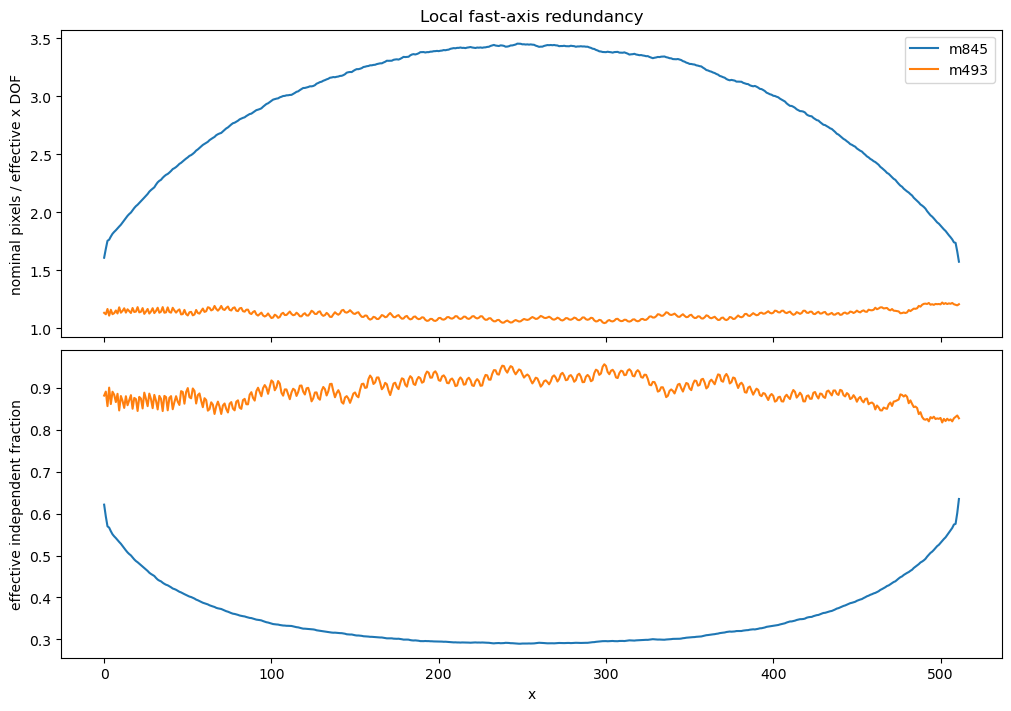

In [ ]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(
    2,
    1,
    figsize=(10, 7),
    sharex=True,
    constrained_layout=True,
)

ax[0].plot(
    info845["redundancy"],
    label="m845",
)

ax[0].plot(
    info493["redundancy"],
    label="m493",
)

ax[0].set_ylabel("nominal pixels / effective x DOF")
ax[0].set_title("Local fast-axis redundancy")
ax[0].legend()


ax[1].plot(
    info845["independent_fraction"],
    label="m845",
)

ax[1].plot(
    info493["independent_fraction"],
    label="m493",
)

ax[1].set_xlabel("x")
ax[1].set_ylabel("effective independent fraction")

# plt.show()
plt.savefig(fig_path / "effective_pixels_m_compare.png")

In [ ]:
for name, info in [
    ("m845", info845),
    ("m493", info493),
]:
    r = info["redundancy"]

    print(name)
    print("  center redundancy:", np.nanmedian(r[230:280]))
    print("  edge redundancy:", np.nanmedian(np.r_[r[20:70], r[440:490]]))
    print("  median redundancy:", np.nanmedian(r))

m845
  center redundancy: 3.43825127188361
  edge redundancy: 2.398013931528425
  median redundancy: 3.1104045255771533
m493
  center redundancy: 1.0758132574262098
  edge redundancy: 1.1498495005643408
  median redundancy: 1.118716485229698


In [ ]:
N_eff_local_approx = np.nansum(info845["independent_fraction"])

print(N_eff_local_approx)

180.5993338016937


# Recover phase domain spectrum

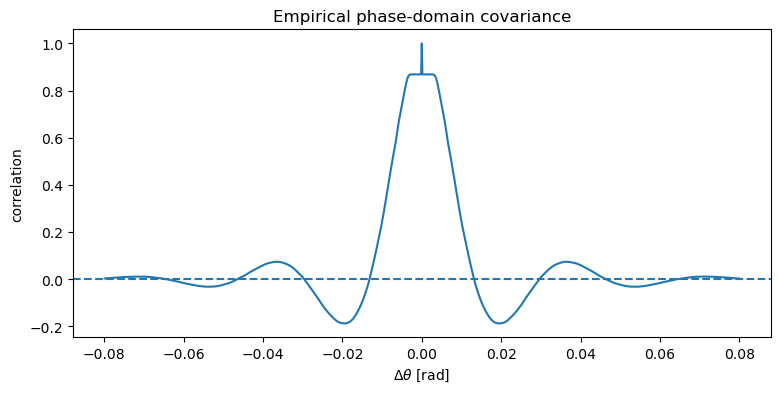

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_phase_domain_spectrum import (
    empirical_phase_covariance,
)

theta, Ktheta, dtheta = empirical_phase_covariance(
    collapsed_294,
    theta_max=0.08,
    n_positive=256,
    smooth_sigma=1.0,
)

plt.figure(figsize=(9, 4))
plt.plot(theta, Ktheta)
plt.axhline(0, ls="--")
plt.xlabel(r"$\Delta\theta$ [rad]")
plt.ylabel("correlation")
plt.title("Empirical phase-domain covariance")
# plt.show()
plt.savefig(fig_path / f"empirical_phase_covariance_m{suffix}.png")

In [ ]:
sys.path.insert(
    0,
    str(
        root_dir
        / "turnover_dynamics"
        / "neuron_detection_caiman"
        / "scanning_artifacts"
    ),
)
from diagnostics_phase_domain_spectrum import covariance_to_spectrum

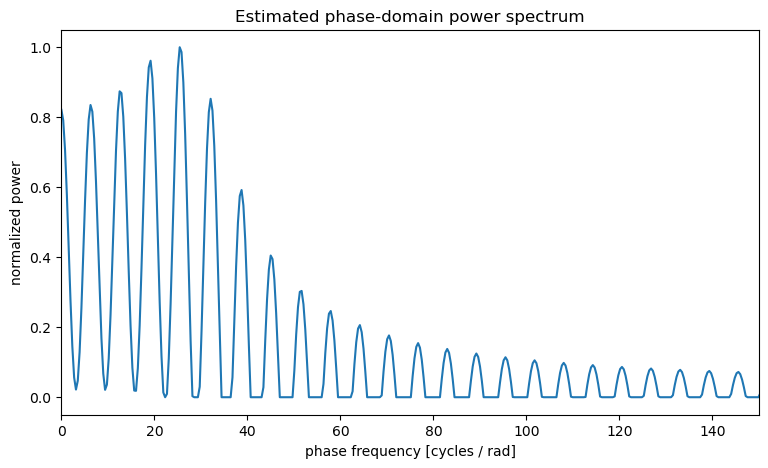

In [ ]:
freq, psd = covariance_to_spectrum(
    theta,
    Ktheta,
)

plt.figure(figsize=(9, 5))

plt.plot(
    freq,
    psd,
)

plt.xlabel("phase frequency [cycles / rad]")
plt.ylabel("normalized power")
plt.title("Estimated phase-domain power spectrum")

plt.xlim(0, 150)
# plt.show()
plt.savefig(fig_path / f"phase_domain_power_spectrum_m{suffix}.png")

In [ ]:
from diagnostics_phase_domain_spectrum import covariance_cosine_spectrum

freq, psd_emp, H_emp = covariance_cosine_spectrum(
    theta_bin,
    K,
    K0=damped_fit["alpha"],
    theta_max=0.08,
    f_max=80,
)

In [73]:
H_emp

array([1.        , 1.0000017 , 1.00000679, ..., 0.        , 0.        ,
       0.        ], shape=(2000,))

In [74]:
theta_model = np.linspace(
    0,
    max(0.20, 6 * damped_fit["sigma"]),
    10000,
)

K_model = damped_sinc_kernel(
    theta_model,
    damped_fit["alpha"],
    damped_fit["tau"],
    damped_fit["sigma"],
)

freq_model = np.linspace(
    0,
    80,
    2000,
)

psd_model = np.empty_like(freq_model)

for i, f in enumerate(freq_model):
    psd_model[i] = 2 * np.trapezoid(
        K_model * np.cos(2 * np.pi * f * theta_model), theta_model
    )

psd_model /= psd_model[0]

H_model = np.sqrt(np.maximum(psd_model, 0))

In [75]:
psd_emp

array([ 1.        ,  1.0000034 ,  1.00001358, ..., -0.01562618,
       -0.01567709, -0.01572831], shape=(2000,))

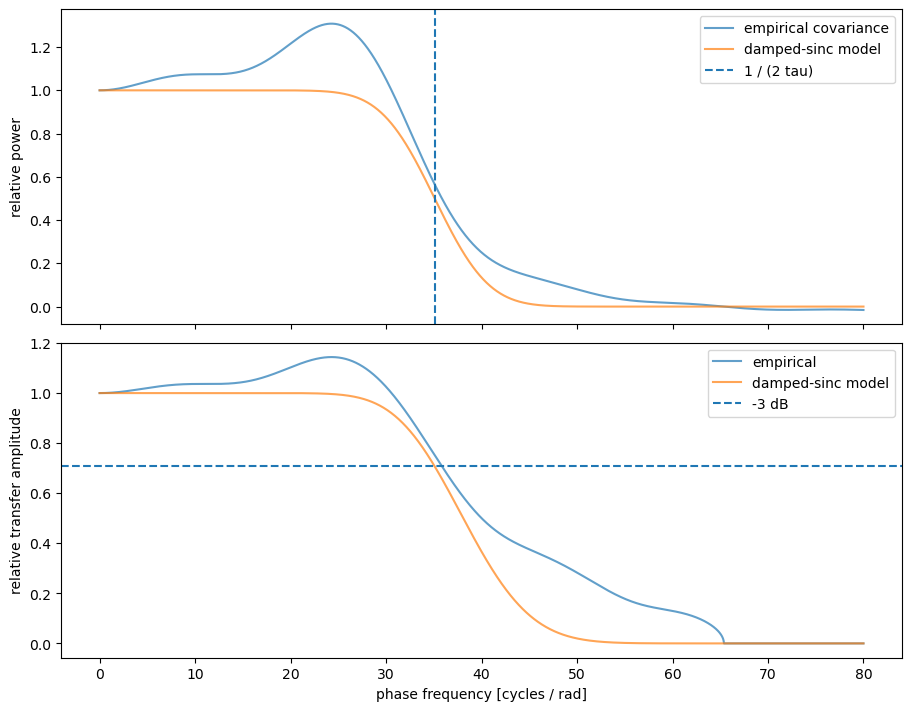

In [80]:
fig, ax = plt.subplots(
    2,
    1,
    figsize=(9, 7),
    sharex=True,
    constrained_layout=True,
)

ax[0].plot(freq, psd_emp, alpha=0.7, label="empirical covariance")

ax[0].plot(freq_model, psd_model, alpha=0.7, label="damped-sinc model")

ax[0].axvline(1 / (2 * damped_fit["tau"]), ls="--", label="1 / (2 tau)")

ax[0].set_ylabel("relative power")
ax[0].legend()


ax[1].plot(freq, H_emp, alpha=0.7, label="empirical")

ax[1].plot(freq_model, H_model, alpha=0.7, label="damped-sinc model")

ax[1].axhline(1 / np.sqrt(2), ls="--", label="-3 dB")

ax[1].set_xlabel("phase frequency [cycles / rad]")
ax[1].set_ylabel("relative transfer amplitude")

ax[1].legend()

# plt.show()
plt.savefig(fig_path / f"phase_domain_spectrum_m{suffix}.png")

In [ ]:
from diagnostics_phase_domain_spectrum import local_bandwidth_from_phase_cutoff

f_cutoff = 1 / (2 * damped_fit["tau"])

spatial_cutoff, sampling_spacing = local_bandwidth_from_phase_cutoff(
    X=512,
    x0=joint_fit["x0"],
    A=joint_fit["A"],
    f_phase_cutoff=f_cutoff,
)

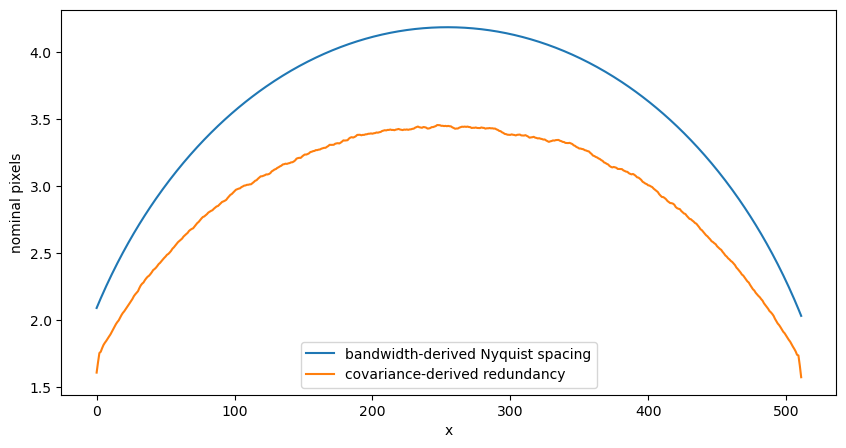

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(sampling_spacing, label="bandwidth-derived Nyquist spacing")

plt.plot(info845["redundancy"], label="covariance-derived redundancy")

plt.xlabel("x")
plt.ylabel("nominal pixels")
plt.legend()

plt.show()
# plt.savefig(fig_path / f"nyquist_vs_redundancy_m{suffix}.png")

```
The problem is probably not primarily a geometric x-mapping error that you can fix by stretching/compressing the image.

The problem is much more likely a phase-domain low-pass / smoothing process, which leaves the image heavily redundant along x, especially in the center.
```

# Attempting reconstruction!

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_pipeline import (
    make_resonant_phase_grids,
    movie_x_to_theta,
    movie_theta_to_x,
)

session_path = Path(
    # "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01"
    "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]

In [ ]:
img_845 = tiff.imread(file_path).astype(np.float32)

In [ ]:
grids = make_resonant_phase_grids(
    X=512,
    x0=joint_fit["x0"],
    A=joint_fit["A"],
    n_theta=512,
)

NameError: name 'joint_fit' is not defined

In [ ]:
m_theta = movie_x_to_theta(img_845[:1000], grids)

m_roundtrip = movie_theta_to_x(m_theta, grids)

In [103]:
img_845.shape

(8989, 512, 512)

In [ ]:
import cv2

cv2.destroyAllWindows()
cv2.waitKey(1)

-1

In [ ]:
from utils.display_videos import display_videos

display_videos(
    [img_845[:1000, ...], m_roundtrip], display_mode="common", percentiles=[20, 99.9]
)

: 

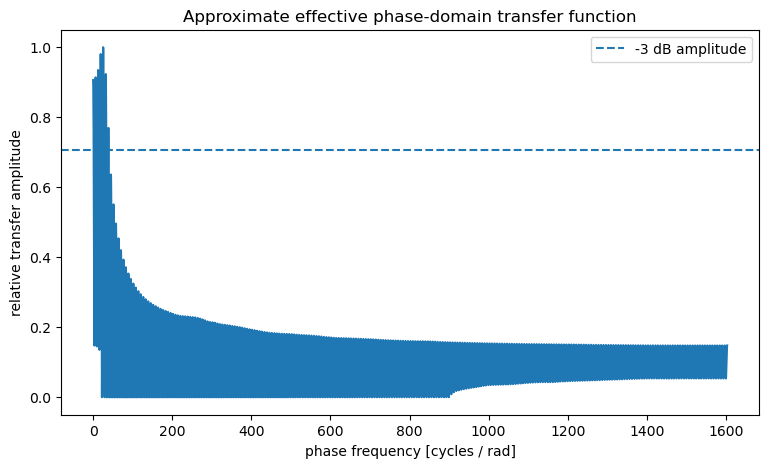

In [ ]:
H = np.sqrt(psd)

plt.figure(figsize=(9, 5))

plt.plot(
    freq,
    H,
)

plt.axhline(1 / np.sqrt(2), ls="--", label="-3 dB amplitude")

plt.xlabel("phase frequency [cycles / rad]")
plt.ylabel("relative transfer amplitude")

plt.title("Approximate effective phase-domain transfer function")

plt.legend()
# plt.show()
plt.savefig(fig_path / f"phase_domain_transfer_function_m{suffix}.png")

In [ ]:
from diagnostics_phase_domain_spectrum import (
    empirical_phase_covariance,
    covariance_to_spectrum,
    crossing_frequency,
)

f_3db = crossing_frequency(freq, H, 1 / np.sqrt(2))

f_10pct = crossing_frequency(freq, H, 0.1)

print("amplitude -3 dB frequency:", f_3db)
print("10% amplitude frequency:", f_10pct)

amplitude -3 dB frequency: 1.370998257737392
10% amplitude frequency: 21.9733025158721


In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    estimate_phase_kernel,
    fit_damped_sinc,
)

theta_bin, K, K_std, count = estimate_phase_kernel(
    collapsed_294,
    n_bins=120,
)

damped_fit = fit_damped_sinc(collapsed_294)

K_corr = Ktheta.copy()

zero = np.argmin(np.abs(theta))

# Use fitted correlated fraction rather than total C(0)=1
K_corr[zero] = damped_fit["alpha"]

freq_corr, psd_corr = covariance_to_spectrum(
    theta,
    K_corr,
)

H_corr = np.sqrt(psd_corr)

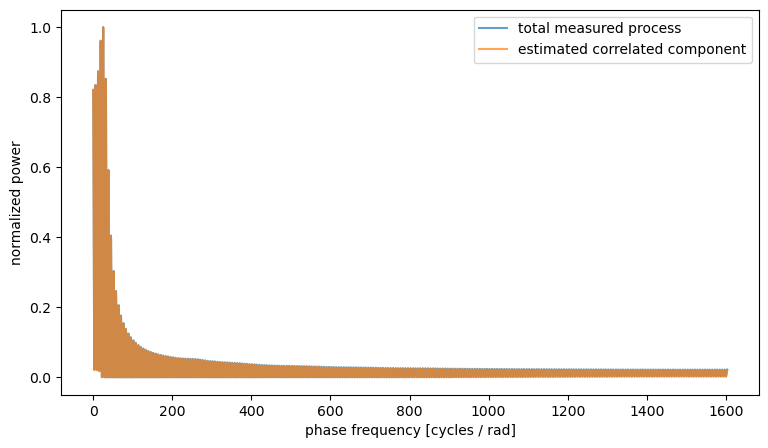

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    freq,
    psd,
    alpha=0.7,
    label="total measured process",
)

plt.plot(
    freq_corr,
    psd_corr,
    alpha=0.7,
    label="estimated correlated component",
)

plt.xlabel("phase frequency [cycles / rad]")
plt.ylabel("normalized power")
plt.legend()
# plt.show()
plt.savefig(fig_path / f"psd_comparison_m{suffix}.png")

In [78]:
## m845
results = diagnose_resonant_scan(img)

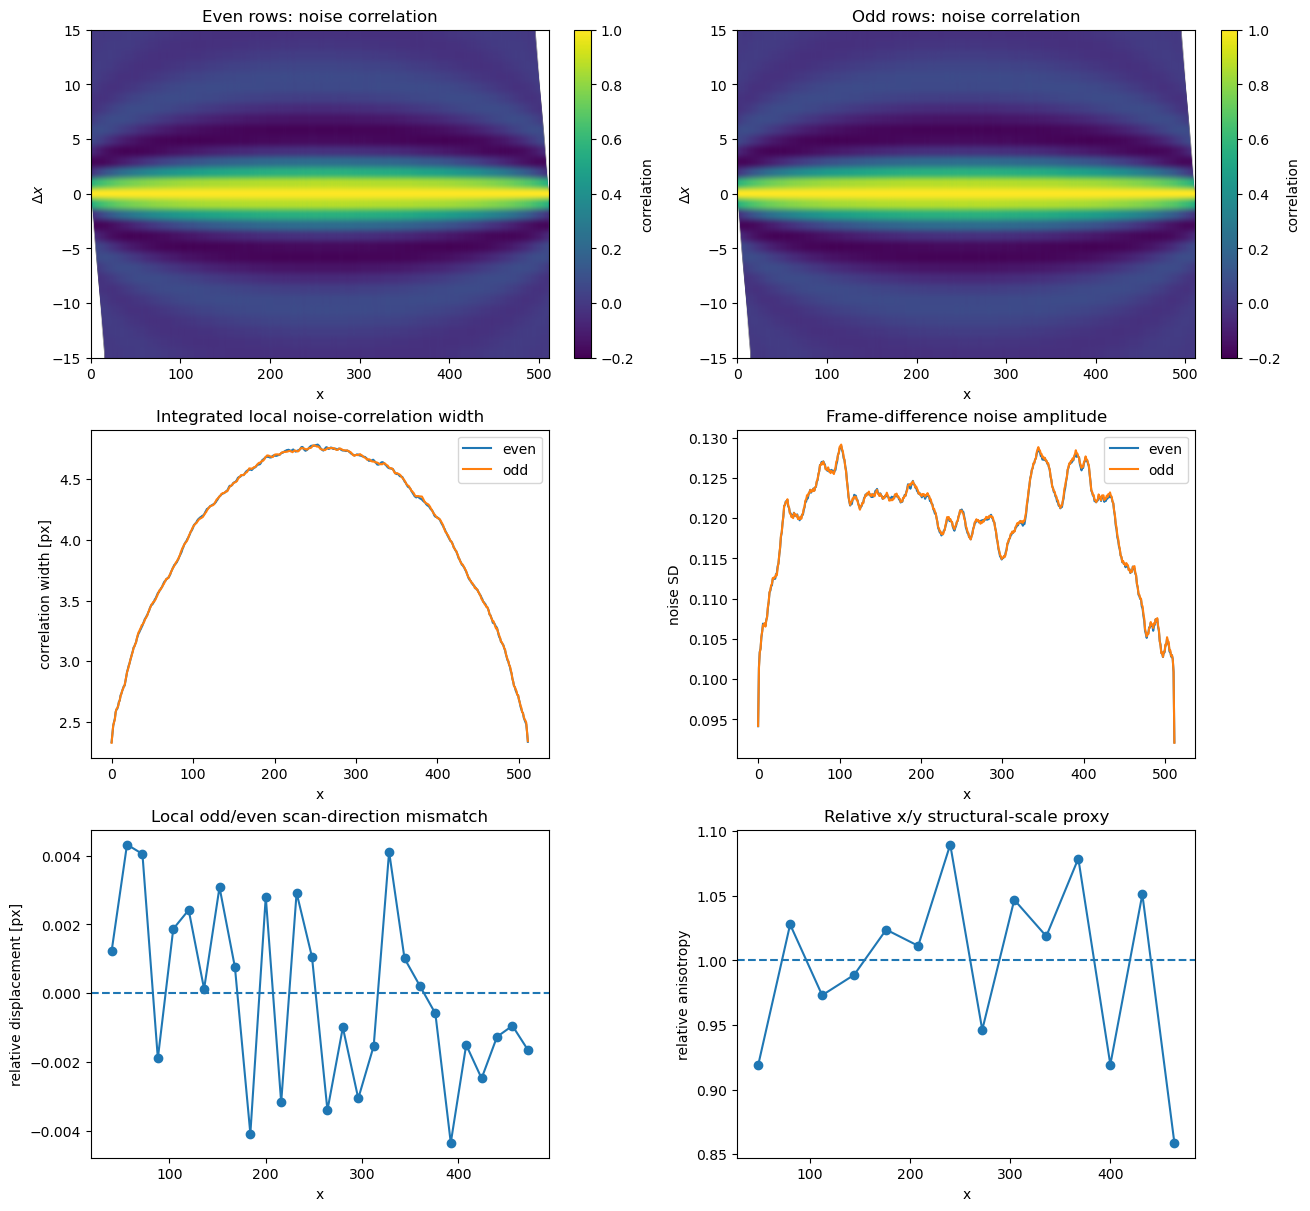

In [79]:
plot_resonant_diagnostics(results)

In [ ]:
## m493
session_path = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/KotaroData/493/Session01/"
)
file_path = session_path / "df1cko#493_m1_hp_x16_x1.5_15v_111um_lres2t.tif"

img = tiff.imread(file_path).astype(np.float32)

In [81]:
results_493 = diagnose_resonant_scan(img)

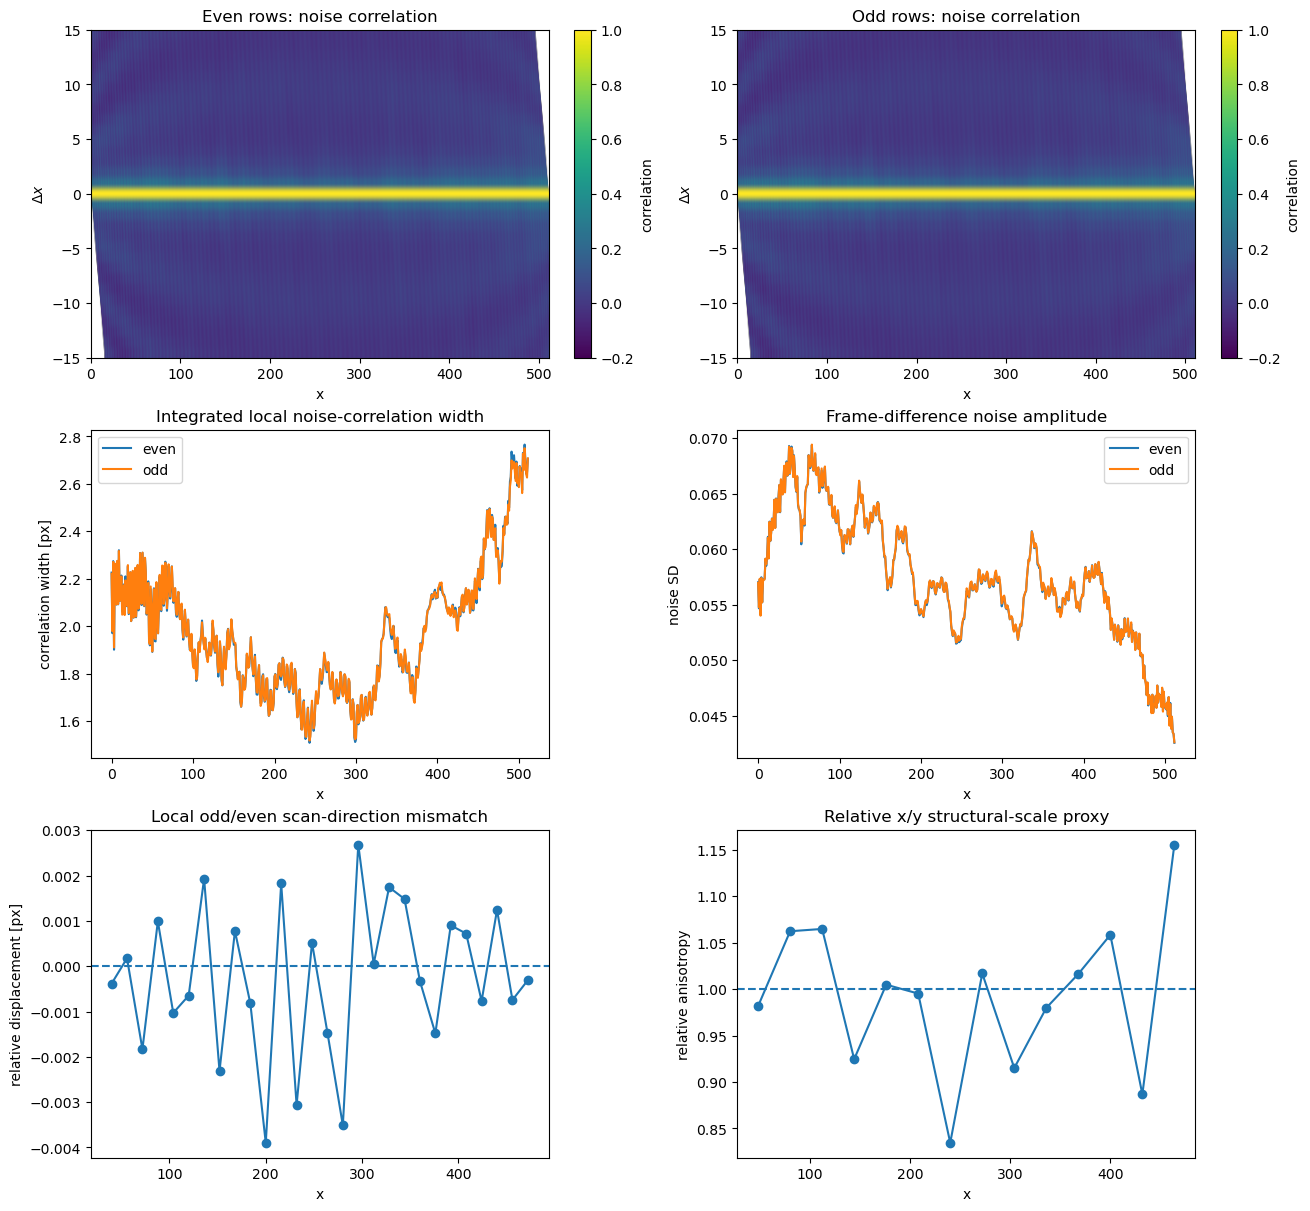

In [82]:
plot_resonant_diagnostics(results_493)

In [58]:
motion_results = resonant_motion_scale_diagnostic(
    img,
    bin_size=3,
    strip_width=96,
    step=24,
)

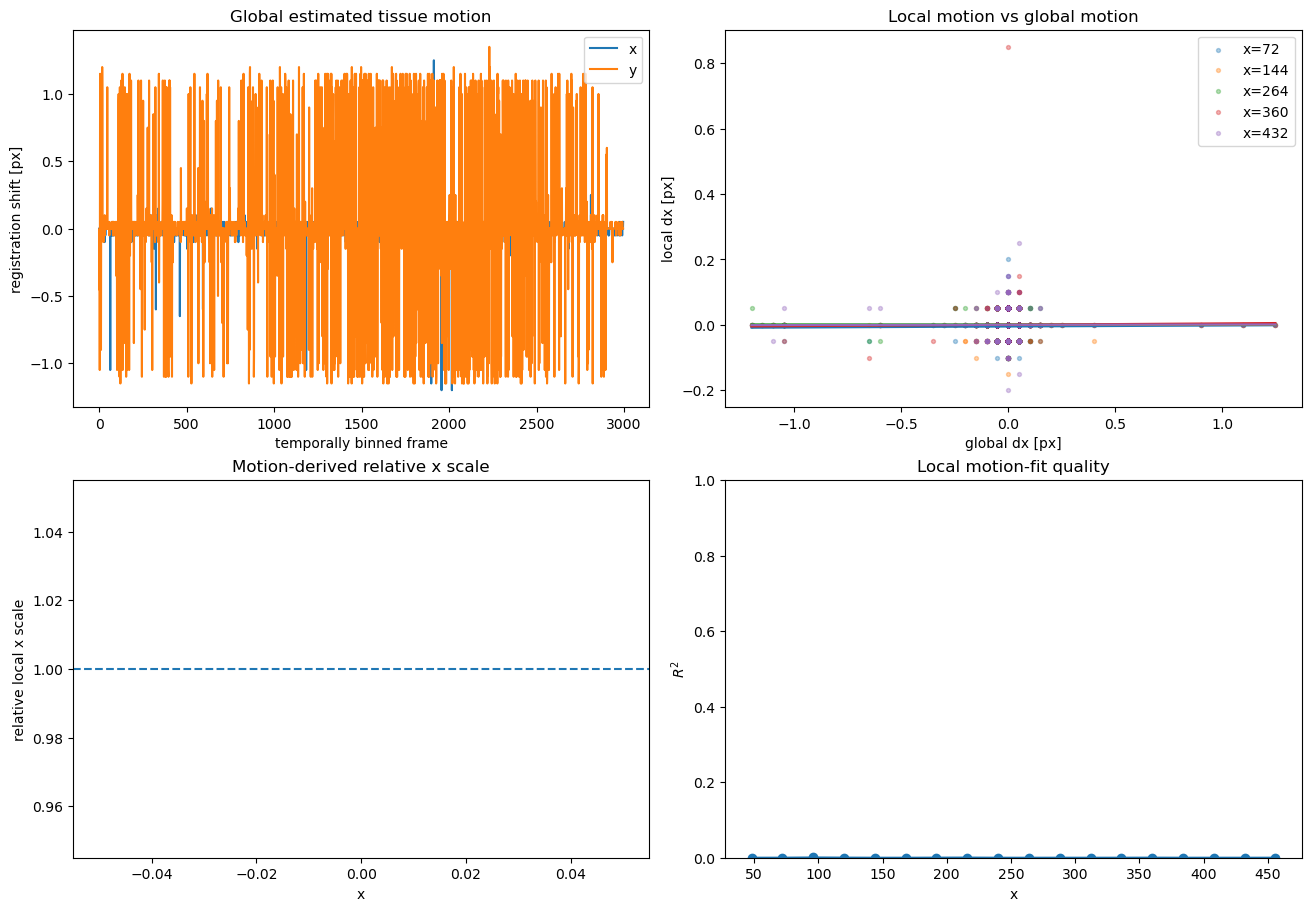

In [ ]:
plot_motion_scale_diagnostic(motion_results)

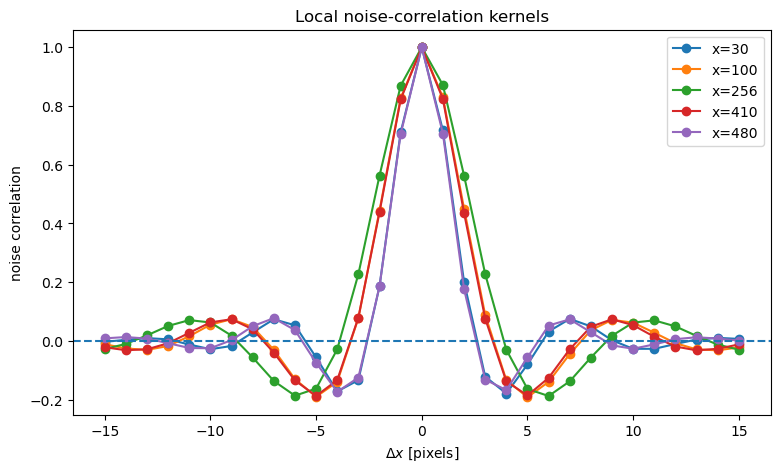

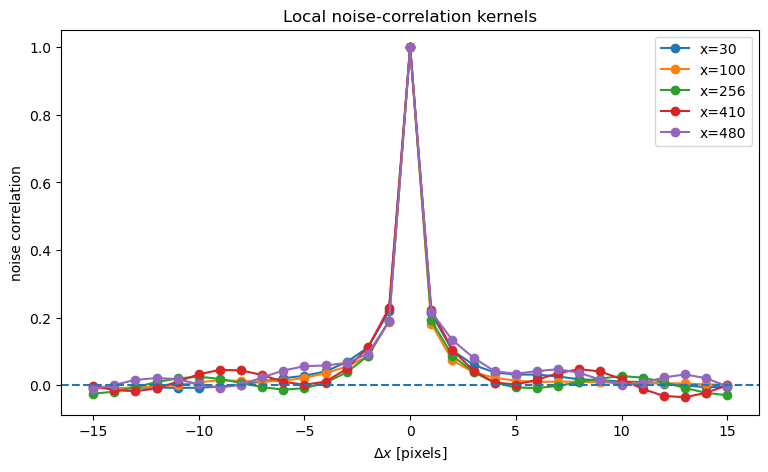

In [ ]:
plot_local_corr_profiles(results, xs=(30, 100, 256, 410, 480))

plot_local_corr_profiles(results_493, xs=(30, 100, 256, 410, 480))